### Project description:
We frame cancer progression as two related prediction tasks. For each patient, the model
takes as input the primary cancer type, treatment, genomic alterations, and estimated
composition of tumor subclones. It then predicts (1) the probability that each detected
subclone survives treatment and (2) the probability of metastasis to each candidate organ.
Using public MSK-MET and MSK-IMPACT data from cBioPortal, we will test whether modeling
tumor heterogeneity improves predictions of cancer progression over simpler clinical and
genomic baselines.

### Exploratory analysis of the datasets

This notebook works through the questions below against three cBioPortal studies:

| Study | What it contributes |
|---|---|
| **MSK-MET** (Cell 2021) | Per-organ metastasis labels and a timestamped diagnosis timeline |
| **MSK-IMPACT 50K** (Cancer Cell 2026) | FACETS allele-specific copy number → cancer cell fractions → heterogeneity |
| **MSK-CHORD** (2024) | Treatment, progression, and per-region tumor-site timelines |

**Two findings up front, because they reshape the questions:**

1. **Neither MSK-MET nor MSK-IMPACT contains treatment data.** MSK-CHORD supplies it.
2. **De novo subclone inference is not viable on a gene panel.** Median ≈5 mutations per
   sample. Heterogeneity is therefore measured as *derived features* from cancer cell
   fractions, not as explicitly clustered subclones. Q6 explains what those features mean
   and tests how far they can be trusted.

Original questions, and where each is answered:

- How many unique patients? How many have matched samples from two timepoints? → **Q1**
- How many cancer types? What are all the different cancer locations? → **Q2**
- How many unique primary tumors? Where are they? → **Q3**
- How many secondary tumors? Where are they? → **Q4**
- What treatments, at what timepoints, with matched post-treatment samples? → **Q9**
- How many patients have genomic data? → **Q8**

Questions added during exploration: **Q5** (when do metastases happen relative to the
biopsy — the leakage boundary), **Q6** (what heterogeneity features actually measure),
**Q7** (does heterogeneity track metastatic burden at all), **Q10** (MSK-CHORD's
progression outcomes).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import loaders as L
import viz

viz.apply_theme()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)

met_s  = L.load_met_sample()
met_p  = L.load_met_patient()
imp_s  = L.load_impact_sample()
imp_p  = L.load_impact_patient()
ch_s   = L.load_chord_sample()
ch_p   = L.load_chord_patient()

het    = pd.read_parquet(L.DERIVED / "het_features.parquet")
cohort = pd.read_parquet(L.DERIVED / "cohort.parquet")
tx     = pd.read_parquet(L.DERIVED / "treatment.parquet")

print(f"MSK-MET        {len(met_s):>6,} samples  {met_s.PATIENT_ID.nunique():>6,} patients")
print(f"MSK-IMPACT 50K {len(imp_s):>6,} samples  {imp_s.PATIENT_ID.nunique():>6,} patients")
print(f"MSK-CHORD      {len(ch_s):>6,} samples  {ch_s.PATIENT_ID.nunique():>6,} patients")
print(f"core cohort    {len(cohort):>6,} samples  (MSK-MET labels + FACETS QC pass)")

MSK-MET        25,775 samples  25,775 patients
MSK-IMPACT 50K 54,331 samples  48,179 patients
MSK-CHORD      25,040 samples  24,950 patients
core cohort    22,410 samples  (MSK-MET labels + FACETS QC pass)


---
## Q1 — Cohort structure and the cross-study join

*How many unique patients are in the dataset? How many patients have matched samples
taken from two timepoints?*

All three studies use the same `P-XXXXXXX` patient and `P-XXXXXXX-TNN-IMN` sample
identifiers, so they join directly. The critical structural fact is that **MSK-MET holds
exactly one sample per patient** — every bit of longitudinal signal comes from the
MSK-IMPACT side.

In [2]:
sets = L.cohorts()
met, impact, chord = sets["met"], sets["impact"], sets["chord"]

overlap = pd.Series({
    "MSK-MET only":              len(met - impact - chord),
    "MET ∩ IMPACT":              len(met & impact - chord),
    "MET ∩ IMPACT ∩ CHORD":      len(met & impact & chord),
    "IMPACT ∩ CHORD":            len(impact & chord - met),
    "MSK-IMPACT only":           len(impact - met - chord),
    "MSK-CHORD only":            len(chord - impact - met),
})
print(overlap.to_string(), "\n")

samples_per_patient = imp_s.PATIENT_ID.value_counts()
multi = samples_per_patient[samples_per_patient >= 2]
print(f"IMPACT patients with >=2 samples: {len(multi):,}")
print(f"MSK-MET samples per patient: {met_s.PATIENT_ID.value_counts().unique()}")

MSK-MET only              324
MET ∩ IMPACT            12436
MET ∩ IMPACT ∩ CHORD    12643
IMPACT ∩ CHORD           6924
MSK-IMPACT only         16176
MSK-CHORD only           5011 

IMPACT patients with >=2 samples: 5,070
MSK-MET samples per patient: [1]


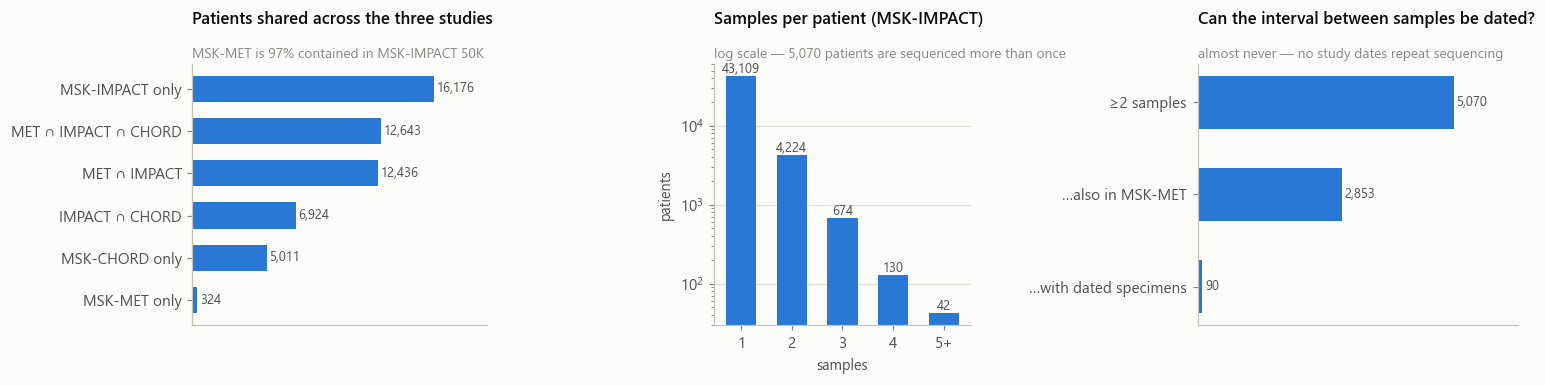

repeat-sequenced patients whose sample interval can be dated: 90 of 5,070
  median interval among those: 1.15 years


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6),
                         gridspec_kw={"width_ratios": [1.15, 1, 1.25]})

# -- cohort overlap: one series, so one color; magnitude by bar length only
ax = axes[0]
o = overlap.sort_values()
bars = ax.barh(o.index, o.values, color=viz.CAT[0], height=0.62)
viz.label_bars(ax, bars, o.values)
ax.set_xlim(0, o.max() * 1.22)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xticks([])
viz.finish(ax, "Patients shared across the three studies",
           subtitle="MSK-MET is 97% contained in MSK-IMPACT 50K")

# -- samples per patient
ax = axes[1]
spp = samples_per_patient.value_counts().sort_index()
spp.index = [str(i) if i < 5 else "5+" for i in spp.index]
spp = spp.groupby(level=0).sum()
bars = ax.bar(spp.index, spp.values, color=viz.CAT[0], width=0.6)
ax.set_yscale("log")
viz.label_bars(ax, bars, spp.values, horizontal=False, pad=0.0)
viz.finish(ax, "Samples per patient (MSK-IMPACT)",
           subtitle="log scale — 5,070 patients are sequenced more than once",
           xlabel="samples", ylabel="patients")

# -- can we actually DATE the interval between a patient's samples?
#    MSK-IMPACT ships no timeline at all; MSK-MET has one sequencing event per
#    patient; only MSK-CHORD's specimen timeline carries repeat dates.
ax = axes[2]
spec = L.load_chord_timeline("specimen")
sizes = spec.groupby("PATIENT_ID").START_DATE.agg(["min", "max", "size"])
dated = sizes[sizes["size"] >= 2]
avail = pd.Series({
    "≥2 samples": len(multi),
    "…also in MSK-MET": int(multi.index.isin(met).sum()),
    "…with dated specimens": len(dated),
})
bars = ax.barh(avail.index[::-1], avail.values[::-1], color=viz.CAT[0],
               height=0.58)
viz.label_bars(ax, bars, avail.values[::-1])
ax.set_xlim(0, avail.max() * 1.25)
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xticks([])
viz.finish(ax, "Can the interval between samples be dated?",
           subtitle="almost never — no study dates repeat sequencing")

plt.tight_layout()
plt.show()

print(f"repeat-sequenced patients whose sample interval can be dated: "
      f"{len(dated):,} of {len(multi):,}")
print(f"  median interval among those: "
      f"{((dated['max'] - dated['min']).median() / 365.25):.2f} years")

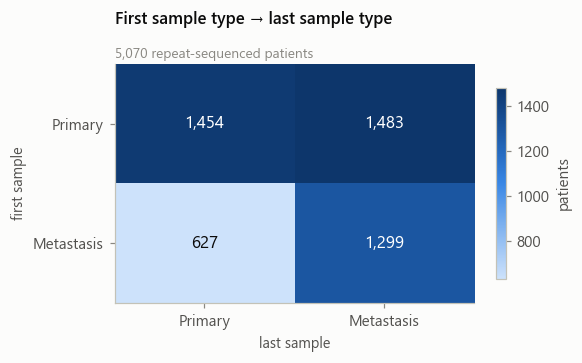

Primary → Metastasis (true progression pairs): 1,483
of these, also in MSK-MET: 893


In [4]:
# Primary -> Metastasis transitions among repeat-sequenced patients: the only
# place in these data where a tumor is observed at two timepoints.
first_last = (imp_s.assign(t=imp_s.SAMPLE_ID.str.extract(r"-T(\d+)-").astype(int))
              .sort_values(["PATIENT_ID", "t"])
              .groupby("PATIENT_ID")
              .agg(first_type=("SAMPLE_TYPE", "first"),
                   last_type=("SAMPLE_TYPE", "last"),
                   n=("SAMPLE_ID", "size")))
fl = first_last[first_last.n >= 2]
keep = ["Primary", "Metastasis"]
xt = pd.crosstab(fl.first_type, fl.last_type).reindex(index=keep, columns=keep)

fig, ax = plt.subplots(figsize=(5.4, 3.4))
im = ax.imshow(xt.values, cmap="seq_blue", aspect="auto")
ax.set_xticks(range(len(keep)), keep); ax.set_yticks(range(len(keep)), keep)
ax.grid(False)
for i in range(len(keep)):
    for j in range(len(keep)):
        v = xt.values[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=11,
                color="#ffffff" if v > xt.values.max() * 0.55 else viz.INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="patients")
viz.finish(ax, "First sample type → last sample type",
           subtitle=f"{len(fl):,} repeat-sequenced patients",
           xlabel="last sample", ylabel="first sample")
plt.tight_layout(); plt.show()

print(f"Primary → Metastasis (true progression pairs): {xt.loc['Primary','Metastasis']:,}")
print(f"of these, also in MSK-MET: "
      f"{fl[(fl.first_type=='Primary')&(fl.last_type=='Metastasis')].index.isin(met).sum():,}")

**Findings.** 25,775 MSK-MET patients, 48,179 MSK-IMPACT, 24,950 MSK-CHORD; 12,643 appear
in all three. MSK-MET holds exactly one sample per patient, so every repeat measurement
comes from MSK-IMPACT: 5,070 patients are sequenced more than once, and 1,483 of those have
a Primary sample followed by a Metastasis sample — 893 of which also carry MSK-MET labels.

**The matched-timepoint question has a worse answer than the counts suggest.** Having two
samples is not the same as being able to place them in time, and *no study in hand dates
repeat sequencing*: MSK-IMPACT 50K ships no timeline files at all, MSK-MET records one
sequencing event per patient, and MSK-CHORD's specimen timeline covers only 90
multi-specimen patients. So the interval between a patient's two tumors is unknown for
4,980 of the 5,070.

---
## Q2 — Cancer types and anatomic sites

*How many cancer types are we working with? What are all of the different cancer
locations?*

Two vocabularies coexist. `CANCER_TYPE` / `ORGAN_SYSTEM` are controlled and clean;
`PRIMARY_SITE` and `METASTATIC_SITE` are free text and dirty — MSK-IMPACT contains both
`Lymph Node` and `Lymph node` as separate values. MSK-MET's 23-value `METASTATIC_SITE`
vocabulary is the normalization target.

In [5]:
print("MSK-MET      CANCER_TYPE   ", met_s.CANCER_TYPE.nunique())
print("MSK-MET      SUBTYPE       ", met_s.SUBTYPE.nunique())
print("MSK-MET      ORGAN_SYSTEM  ", met_s.ORGAN_SYSTEM.nunique())
print("MSK-MET      PRIMARY_SITE  ", met_s.PRIMARY_SITE.nunique())
print("MSK-IMPACT   CANCER_TYPE   ", imp_s.CANCER_TYPE.nunique())
print("MSK-IMPACT   PRIMARY_SITE  ", imp_s.PRIMARY_SITE.nunique())
print()
for col, df, name in [("PRIMARY_SITE", imp_s, "IMPACT PRIMARY_SITE"),
                      ("METASTATIC_SITE", imp_s, "IMPACT METASTATIC_SITE")]:
    raw = df[col].nunique()
    norm = L.normalize_site(df[col]).nunique()
    print(f"{name:26s} raw {raw:>4}  ->  normalized {norm:>4}   "
          f"({raw - norm} case/whitespace duplicates)")

MSK-MET      CANCER_TYPE    27
MSK-MET      SUBTYPE        50
MSK-MET      ORGAN_SYSTEM   10
MSK-MET      PRIMARY_SITE   190
MSK-IMPACT   CANCER_TYPE    65
MSK-IMPACT   PRIMARY_SITE   363

IMPACT PRIMARY_SITE        raw  363  ->  normalized  318   (45 case/whitespace duplicates)
IMPACT METASTATIC_SITE     raw  338  ->  normalized  301   (37 case/whitespace duplicates)


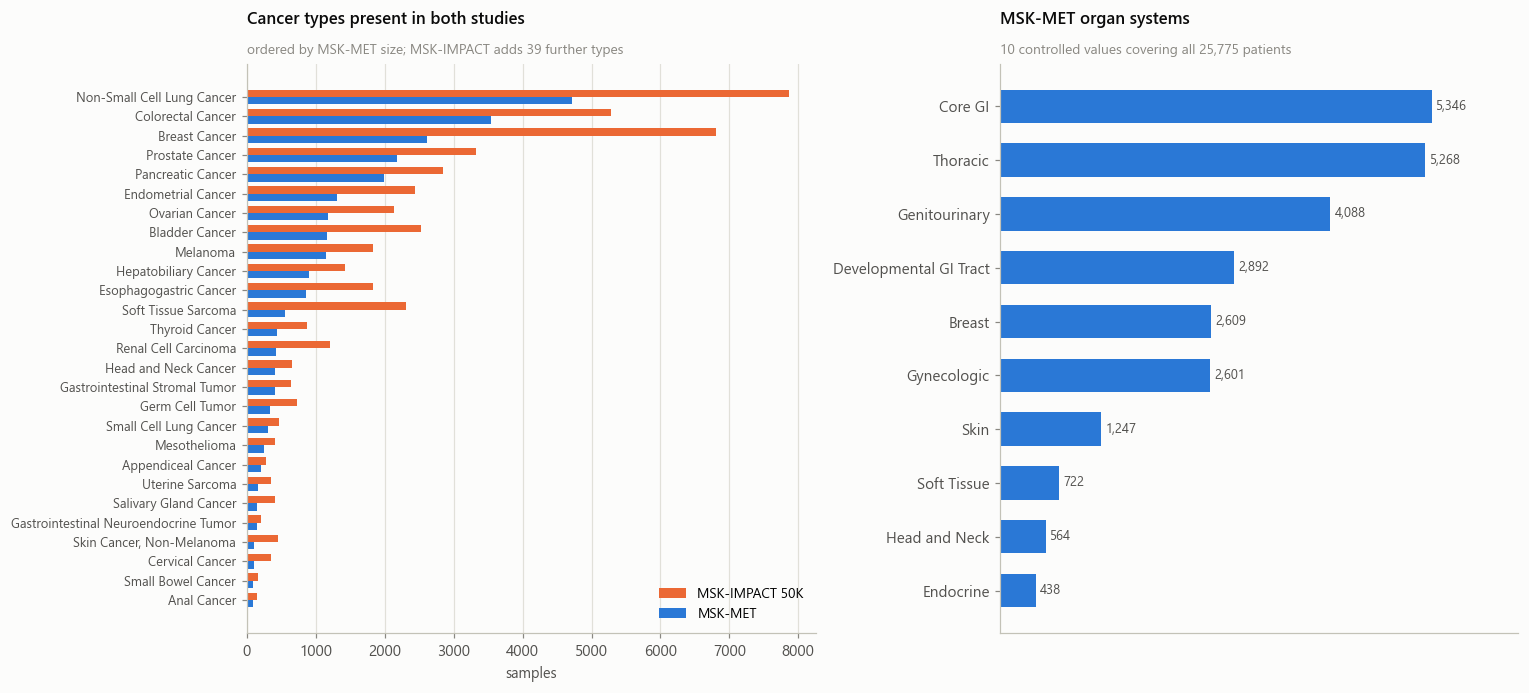

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4),
                         gridspec_kw={"width_ratios": [1.1, 1]})

# -- paired bars: two series, so a legend is required
ax = axes[0]
m = met_s.CANCER_TYPE.value_counts()
i = imp_s.CANCER_TYPE.value_counts().reindex(m.index).fillna(0)
order = m.sort_values().index
y = np.arange(len(order)); h = 0.38
ax.barh(y + h/2, i.loc[order], height=h, color=viz.CAT[1], label="MSK-IMPACT 50K")
ax.barh(y - h/2, m.loc[order], height=h, color=viz.CAT[0], label="MSK-MET")
ax.set_yticks(y, order, fontsize=8.5)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.finish(ax, "Cancer types present in both studies",
           subtitle="ordered by MSK-MET size; MSK-IMPACT adds 39 further types",
           xlabel="samples")

# -- organ system: single series, single color
ax = axes[1]
os_ = met_s.ORGAN_SYSTEM.value_counts().sort_values()
bars = ax.barh(os_.index, os_.values, color=viz.CAT[0], height=0.62)
viz.label_bars(ax, bars, os_.values)
ax.set_xlim(0, os_.max() * 1.2)
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xticks([])
viz.finish(ax, "MSK-MET organ systems",
           subtitle="10 controlled values covering all 25,775 patients")

plt.tight_layout(); plt.show()

In [7]:
# Which cancer types survive the join with enough patients to model per-type?
core_ct = cohort.CANCER_TYPE.value_counts()
under = core_ct[core_ct < 100]
print(f"core-cohort cancer types: {len(core_ct)}")
print(f"  >= 500 patients: {(core_ct >= 500).sum()}")
print(f"  100-499        : {((core_ct >= 100) & (core_ct < 500)).sum()}")
print(f"  < 100 (underpowered for per-type models): {len(under)}  "
      f"covering {under.sum():,} patients")
print()
print(under.to_string())

core-cohort cancer types: 27
  >= 500 patients: 12
  100-499        : 11
  < 100 (underpowered for per-type models): 4  covering 355 patients

CANCER_TYPE
Skin Cancer, Non-Melanoma    99
Cervical Cancer              98
Small Bowel Cancer           80
Anal Cancer                  78


**Findings.** MSK-MET spans 27 cancer types, 50 subtypes and 10 organ systems; MSK-IMPACT
spans 65 types. The controlled vocabularies are clean and usable as-is.

The free-text site fields are not. Normalizing case and whitespace alone collapses
MSK-IMPACT's `PRIMARY_SITE` from 363 to 318 values and `METASTATIC_SITE` from 338 to 301 —
45 and 37 pure duplicates that would otherwise fragment into separate categories. Real
harmonization to MSK-MET's 23-value vocabulary needs a hand-written map, not just
`str.title()`.

For modeling, 23 of the core cohort's 27 cancer types have ≥100 patients (12 have ≥500).
The four below that threshold — non-melanoma skin, cervical, small bowel and anal cancer,
355 patients combined — cannot support per-type models and should either be pooled into a
pan-cancer stratum or excluded explicitly.

---
## Q3 — Primary tumors

*How many unique primary tumors do we have? What are the primary tumor locations?*

"Primary" is ambiguous in these files and the two studies disagree. `SAMPLE_TYPE` records
**where the sequenced biopsy was taken from**; `DISEASE_STATUS` records **whether the
patient had metastatic disease**. A primary-site biopsy from a patient with distant
metastases is `SAMPLE_TYPE = Primary` but `DISEASE_STATUS = Metastasis`. Resolving this is
a prerequisite for any label definition.

DISEASE_STATUS    Primary  Metastasis  Unknown
SAMPLE_TYPE                                   
Primary             20718       11011     1149
Metastasis              0       20820       10
Local Recurrence      100         142        3
Unknown                 0           0      378 

MSK-MET SAMPLE_TYPE: {'Primary': 15632, 'Metastasis': 10143}


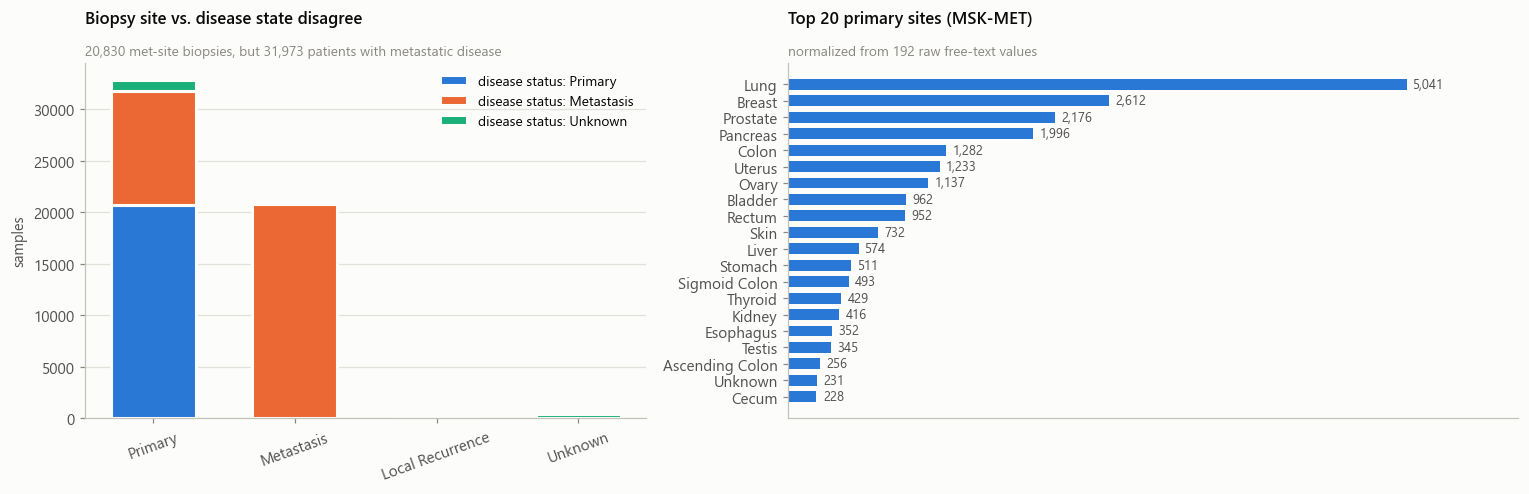

In [8]:
xt = pd.crosstab(imp_s.SAMPLE_TYPE, imp_s.DISEASE_STATUS)
xt = xt.reindex(index=["Primary", "Metastasis", "Local Recurrence", "Unknown"],
                columns=["Primary", "Metastasis", "Unknown"]).fillna(0).astype(int)
print(xt.to_string(), "\n")
print("MSK-MET SAMPLE_TYPE:", met_s.SAMPLE_TYPE.value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6),
                         gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
labels = list(xt.columns)
bottom = np.zeros(len(xt))
for k, col in enumerate(labels):
    ax.bar(xt.index, xt[col], bottom=bottom, color=viz.CAT[k], width=0.6,
           label=f"disease status: {col}",
           edgecolor=viz.SURFACE, linewidth=2)   # 2px surface gap, not a border
    bottom += xt[col].values
ax.legend(loc="upper right")
ax.tick_params(axis="x", labelrotation=20)
viz.finish(ax, "Biopsy site vs. disease state disagree",
           subtitle="20,830 met-site biopsies, but 31,973 patients with metastatic disease",
           ylabel="samples")

ax = axes[1]
sites = L.normalize_site(met_s.PRIMARY_SITE).value_counts().head(20).sort_values()
bars = ax.barh(sites.index, sites.values, color=viz.CAT[0], height=0.66)
viz.label_bars(ax, bars, sites.values)
ax.set_xlim(0, sites.max() * 1.18)
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xticks([])
viz.finish(ax, "Top 20 primary sites (MSK-MET)",
           subtitle="normalized from 192 raw free-text values")
plt.tight_layout(); plt.show()

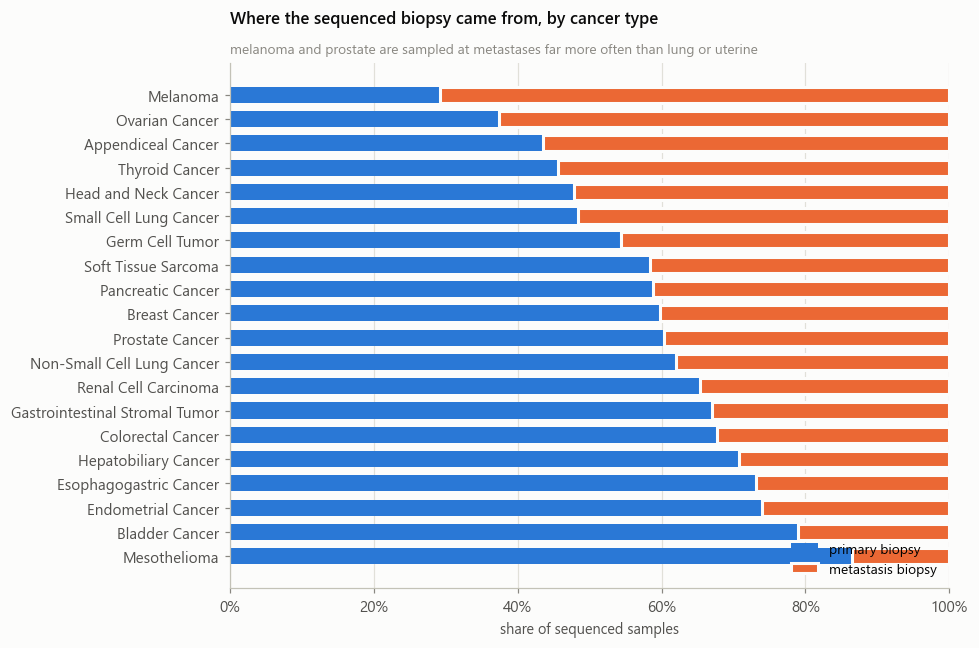

In [9]:
# Which cancers are systematically biopsied at a metastatic site rather than the primary?
ct = (met_s.groupby("CANCER_TYPE").SAMPLE_TYPE
      .value_counts(normalize=True).unstack().fillna(0))
ct = ct[ct.index.isin(met_s.CANCER_TYPE.value_counts().head(20).index)]
ct = ct.sort_values("Metastasis")

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ct.index, ct.Primary, color=viz.CAT[0], height=0.66, label="primary biopsy")
ax.barh(ct.index, ct.Metastasis, left=ct.Primary, color=viz.CAT[1], height=0.66,
        label="metastasis biopsy", edgecolor=viz.SURFACE, linewidth=2)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.finish(ax, "Where the sequenced biopsy came from, by cancer type",
           subtitle="melanoma and prostate are sampled at metastases far more often than lung or uterine",
           xlabel="share of sequenced samples")
plt.tight_layout(); plt.show()

**Findings.** The crosstab settles the ambiguity, and the answer matters. Of MSK-IMPACT's
32,878 `SAMPLE_TYPE = Primary` samples, **11,011 come from patients whose disease was
already metastatic** — the surgeon biopsied the primary tumor, but the cancer had spread.
Only 20,718 are primary biopsies from genuinely localized disease.

So `SAMPLE_TYPE` answers "where did this tissue come from" and `DISEASE_STATUS` answers
"how advanced was the disease." Using the first as a proxy for the second mislabels one
sample in five. **`DISEASE_STATUS` is the correct field for disease state; `SAMPLE_TYPE`
is the correct field for a biopsy-site covariate** — and the latter genuinely belongs in
the model, because CCF estimates measured from a liver metastasis and from a primary
breast tumor are not directly comparable.

Which one gets sampled is strongly cancer-dependent: prostate and melanoma are biopsied at
metastatic sites far more often than uterine or lung tumors, so biopsy site is confounded
with cancer type and cannot be treated as a nuisance variable.

---
## Q4 — Metastatic sites and tropism

*How many secondary tumors are we working with? What are the locations?*

The right label source is the 21 `DMETS_DX_*` flags, **not** `METASTATIC_SITE`.
`METASTATIC_SITE` names the one site that happened to be biopsied; the `DMETS_DX_*` flags
record every organ with distant metastasis. `MET_SITE_COUNT` is their sum — verified below.

In [10]:
flags = met_s[L.DMETS_COLS].eq("Yes")
print("MET_SITE_COUNT == sum(DMETS_DX_*):",
      (flags.sum(axis=1) == met_s.MET_SITE_COUNT).all())
print(f"patients with >=1 distant met: {(met_s.MET_SITE_COUNT > 0).sum():,} "
      f"({(met_s.MET_SITE_COUNT > 0).mean():.1%})")
print(f"total organ-level metastases: {flags.values.sum():,}")

organs = [c.replace("DMETS_DX_", "") for c in L.DMETS_COLS]
tropism = (met_s.groupby("CANCER_TYPE")[L.DMETS_COLS]
           .apply(lambda d: d.eq("Yes").mean()))
tropism.columns = organs
top_ct = met_s.CANCER_TYPE.value_counts().head(18).index
tropism = tropism.loc[top_ct]
tropism = tropism.drop(columns=["UNSPECIFIED"])

MET_SITE_COUNT == sum(DMETS_DX_*): True
patients with >=1 distant met: 21,546 (83.6%)
total organ-level metastases: 77,634


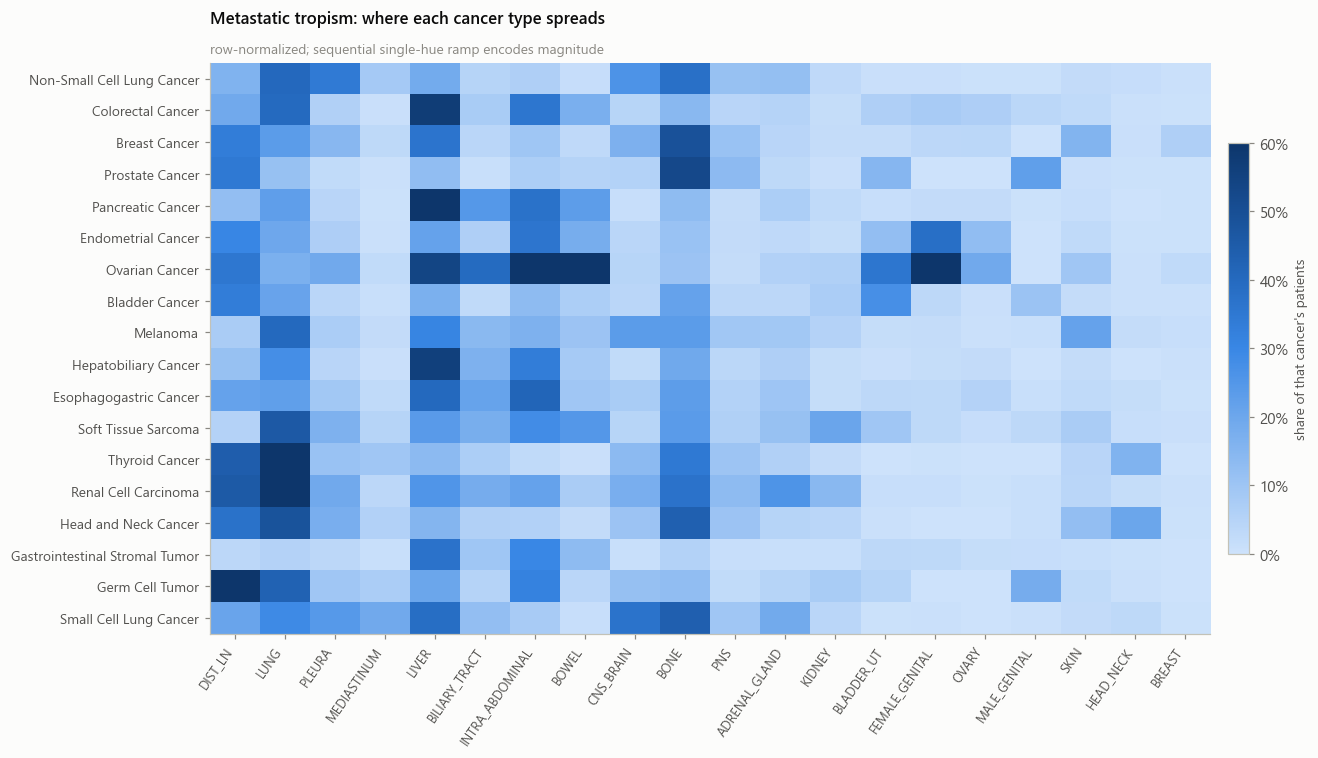

In [11]:
fig, ax = plt.subplots(figsize=(13, 7))
im = ax.imshow(tropism.values, cmap="seq_blue", aspect="auto", vmin=0, vmax=0.6)
ax.set_xticks(range(tropism.shape[1]), tropism.columns, rotation=55,
              ha="right", fontsize=8.5)
ax.set_yticks(range(tropism.shape[0]), tropism.index, fontsize=9)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.72, pad=0.015)
cb.set_label("share of that cancer's patients", color=viz.INK_2, fontsize=9)
cb.ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
viz.finish(ax, "Metastatic tropism: where each cancer type spreads",
           subtitle="row-normalized; sequential single-hue ramp encodes magnitude")
plt.tight_layout(); plt.show()

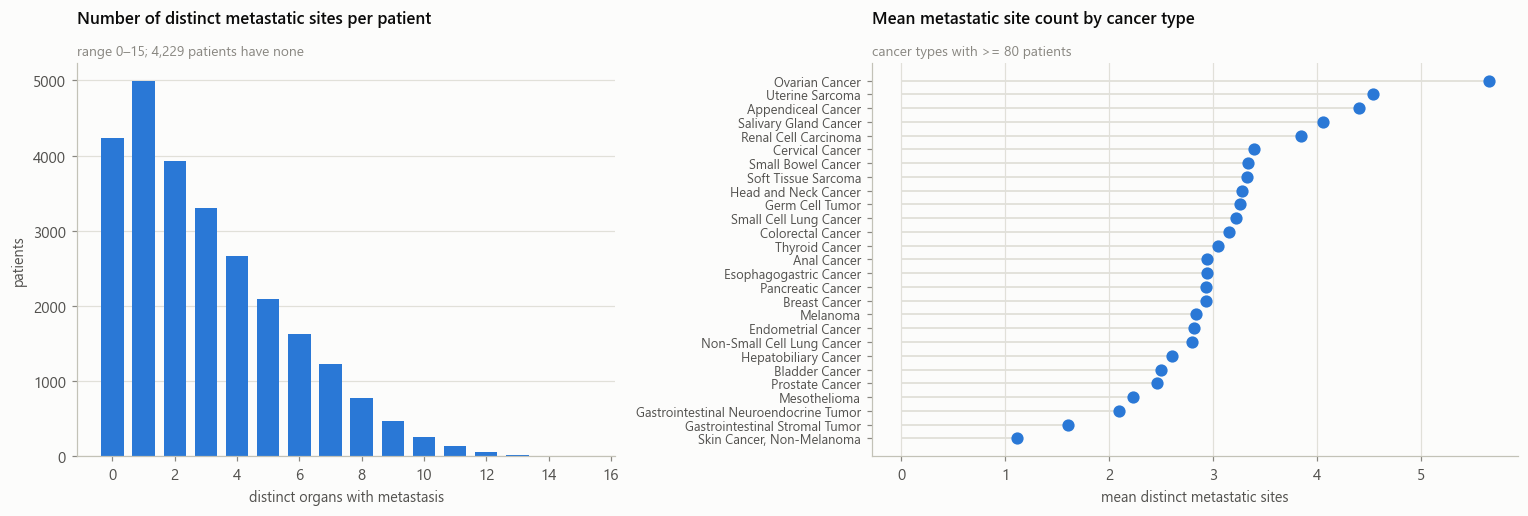

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8),
                         gridspec_kw={"width_ratios": [1, 1.2]})

ax = axes[0]
msc = met_s.MET_SITE_COUNT.value_counts().sort_index()
bars = ax.bar(msc.index, msc.values, color=viz.CAT[0], width=0.72)
viz.finish(ax, "Number of distinct metastatic sites per patient",
           subtitle=f"range 0–{int(met_s.MET_SITE_COUNT.max())}; "
                    f"{(met_s.MET_SITE_COUNT == 0).sum():,} patients have none",
           xlabel="distinct organs with metastasis", ylabel="patients")

ax = axes[1]
mean_sites = (met_s.groupby("CANCER_TYPE").MET_SITE_COUNT.agg(["mean", "size"])
              .query("size >= 80").sort_values("mean"))
ax.hlines(mean_sites.index, 0, mean_sites["mean"], color=viz.GRID, lw=1.2)
ax.plot(mean_sites["mean"], mean_sites.index, "o", color=viz.CAT[0], ms=7)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
viz.finish(ax, "Mean metastatic site count by cancer type",
           subtitle="cancer types with >= 80 patients",
           xlabel="mean distinct metastatic sites")
plt.tight_layout(); plt.show()

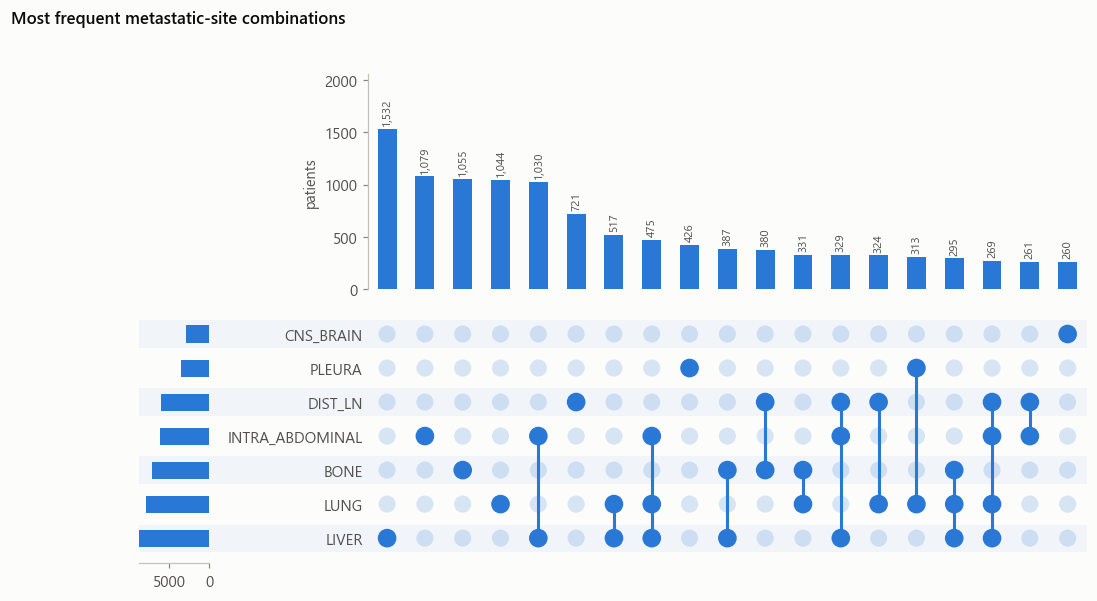

In [13]:
from upsetplot import UpSet, from_indicators

# Co-occurrence matters for a multi-label organ model: a bar chart of marginal
# frequencies hides which organs travel together.
big = ["LIVER", "LUNG", "BONE", "DIST_LN", "CNS_BRAIN", "PLEURA", "INTRA_ABDOMINAL"]
ind = met_s[[f"DMETS_DX_{o}" for o in big]].eq("Yes")
ind.columns = big
ind = ind[ind.any(axis=1)]

# show_counts=True crashes at draw time with this matplotlib version, so the
# counts are labelled directly on the intersection bars instead.
fig = plt.figure(figsize=(11.5, 5.8))
up = UpSet(from_indicators(lambda d: d, data=ind), min_subset_size=250,
           sort_by="cardinality", show_counts=False, facecolor=viz.CAT[0])
res = up.plot(fig=fig)

ax = res["intersections"]
ax.grid(axis="y"); ax.grid(axis="x", visible=False)
for p in ax.patches:
    h = p.get_height()
    ax.text(p.get_x() + p.get_width() / 2, h + ax.get_ylim()[1] * 0.02,
            f"{int(h):,}", ha="center", va="bottom", fontsize=7.5,
            color=viz.INK_2, rotation=90)
ax.set_ylim(0, ax.get_ylim()[1] * 1.28)
ax.set_ylabel("patients", color=viz.INK_2, fontsize=9.5)
res["totals"].grid(False)
fig.suptitle("Most frequent metastatic-site combinations", x=0.02, ha="left",
             fontsize=11, fontweight="semibold", color=viz.INK)
plt.show()

**Findings.** `MET_SITE_COUNT` equals the sum of the 21 `DMETS_DX_*` flags for **every**
patient, so the label set is internally consistent and either representation can be used.
21,546 patients (83.6%) have at least one distant metastasis, totalling 77,634 organ-level
events.

The tropism heatmap reproduces the known biology, which is a good validity check on the
pipeline: colorectal and pancreatic cancers go to the liver, prostate and breast to bone,
thyroid and renal to lung, ovarian throughout the abdomen. Tropism is strongly
cancer-type-specific, so **a pan-cancer per-organ model must condition on cancer type** —
otherwise it will mostly learn the marginal frequency of each organ.

The UpSet plot shows why a multi-label model is the right form rather than 21 independent
binary classifiers: the most common patterns are combinations (liver+lung, liver+bone,
lung+distant lymph), and organ co-occurrence carries real signal that independent
classifiers would discard.

---
## Q5 — When do metastases happen relative to the biopsy?

This question decides whether the project predicts anything at all.

MSK-MET's diagnosis timeline records **125,866 timestamped per-organ metastasis events**.
Its dates are days since birth, so subtracting each patient's sequencing date puts every
event on a *days-from-biopsy* axis. Events at or before day 0 describe disease already
present when the tumor was sequenced — a model "predicting" those is reading the answer off
its own input. Only events after day 0 are genuinely prospective.

In [14]:
dx = L.anchor_met_to_sequencing(L.load_met_timeline("diagnosis"))
dx["organ"] = dx.SUBTYPE.map(L.TIMELINE_SUBTYPE_TO_ORGAN)
dx = dx[dx.organ.notna()]

PERI = 30
window = np.where(dx.DAYS_FROM_SEQ < -PERI, "before",
         np.where(dx.DAYS_FROM_SEQ > PERI, "after", "peri"))
dx["window"] = window
print(dx.window.value_counts().to_string())
print(f"\npatients with >=1 event after sequencing: "
      f"{dx[dx.window=='after'].PATIENT_ID.nunique():,}")

window
before    55991
after     40060
peri      29815

patients with >=1 event after sequencing: 11,120


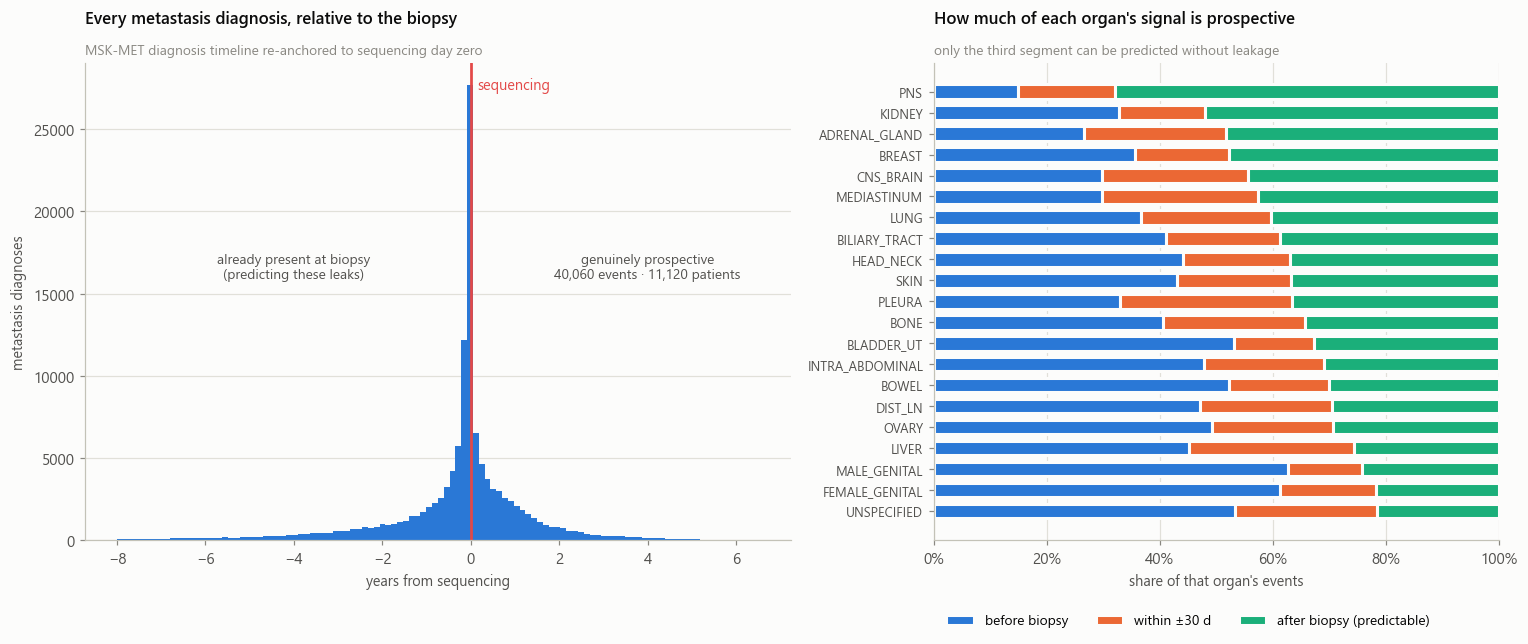

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={"width_ratios": [1.25, 1]})

# -- all metastasis events on one timeline. The story here is a single
#    boundary, so one series and one color carry it.
ax = axes[0]
d = dx.DAYS_FROM_SEQ / 365.25
d = d[(d > -8) & (d < 8)]
ax.hist(d, bins=110, color=viz.CAT[0], rwidth=1.0)
ax.axvline(0, color=viz.CAT[7], lw=1.8)
top = ax.get_ylim()[1]
ax.text(0.15, top * 0.97, "sequencing", color=viz.CAT[7], fontsize=9.5, va="top")
ax.annotate("already present at biopsy\n(predicting these leaks)",
            xy=(-4, top * 0.55), color=viz.INK_2, fontsize=9, ha="center")
ax.annotate("genuinely prospective\n40,060 events · 11,120 patients",
            xy=(4, top * 0.55), color=viz.INK_2, fontsize=9, ha="center")
viz.finish(ax, "Every metastasis diagnosis, relative to the biopsy",
           subtitle="MSK-MET diagnosis timeline re-anchored to sequencing day zero",
           xlabel="years from sequencing", ylabel="metastasis diagnoses")

# -- prospective share per organ
ax = axes[1]
share = (dx.groupby("organ").window.value_counts(normalize=True).unstack()
         .fillna(0).sort_values("after"))
labels = ["before", "peri", "after"]
left = np.zeros(len(share))
for k, w in enumerate(labels):
    ax.barh(share.index, share[w], left=left, height=0.68, color=viz.CAT[k],
            label={"before": "before biopsy", "peri": "within ±30 d",
                   "after": "after biopsy (predictable)"}[w],
            edgecolor=viz.SURFACE, linewidth=2)
    left += share[w].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
# Bars span the full width, so the legend sits below the axis, never over data.
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=3)
viz.finish(ax, "How much of each organ's signal is prospective",
           subtitle="only the third segment can be predicted without leakage",
           xlabel="share of that organ's events")
plt.tight_layout(); plt.show()

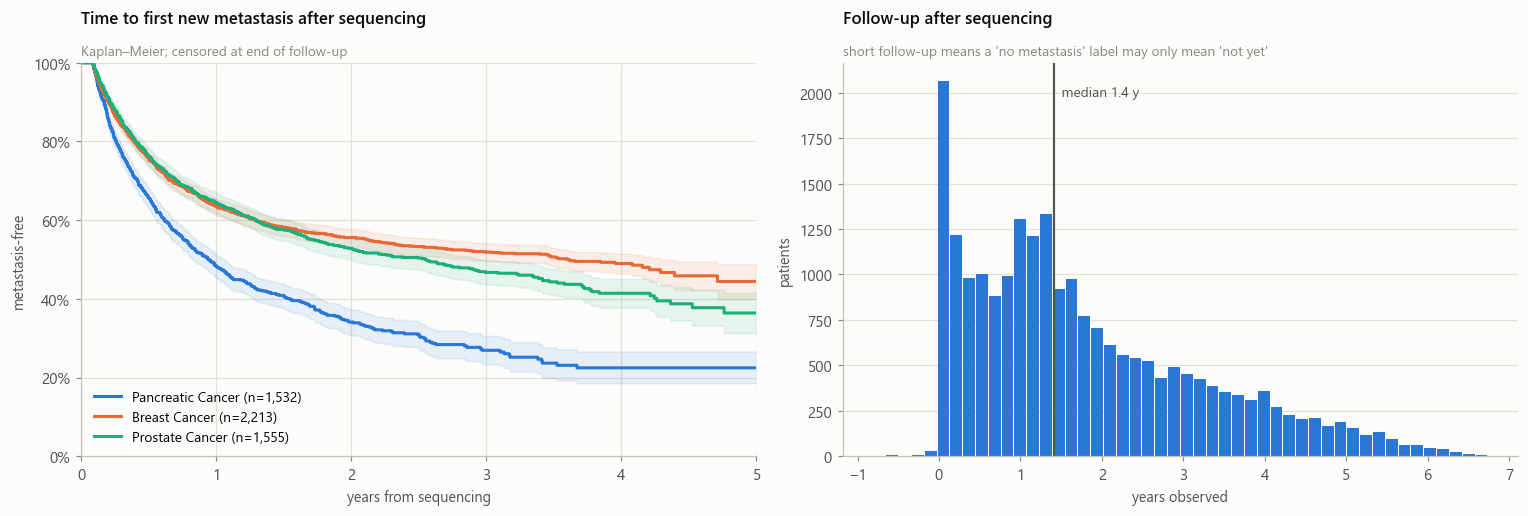

core-cohort patients with <1 year of follow-up: 34.8%


In [16]:
from lifelines import KaplanMeierFitter

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# -- time to first metastasis after sequencing, by cancer type (cap at 3 slots
#    for an all-pairs form; the rest would breach the CVD floor)
ax = axes[0]
kmf = KaplanMeierFitter()
for k, ct in enumerate(["Pancreatic Cancer", "Breast Cancer", "Prostate Cancer"]):
    sub = cohort[cohort.CANCER_TYPE == ct]
    d = sub[sub.T_ANY_MET.notna() & (sub.T_ANY_MET > 0)]
    kmf.fit(d.T_ANY_MET / 365.25, d.E_ANY_MET, label=f"{ct} (n={len(d):,})")
    kmf.plot_survival_function(ax=ax, color=viz.CAT[k], ci_alpha=0.10, lw=2)
ax.set_xlim(0, 5); ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="lower left")
viz.finish(ax, "Time to first new metastasis after sequencing",
           subtitle="Kaplan–Meier; censored at end of follow-up",
           xlabel="years from sequencing", ylabel="metastasis-free")

# -- follow-up adequacy
ax = axes[1]
fu = cohort.followup_days.dropna() / 365.25
fu = fu[(fu > -1) & (fu < 12)]
ax.hist(fu, bins=48, color=viz.CAT[0], rwidth=0.92)
med = fu.median()
ax.axvline(med, color=viz.INK_2, lw=1.4)
ax.text(med, ax.get_ylim()[1]*0.94, f"  median {med:.1f} y", color=viz.INK_2,
        fontsize=9, va="top")
viz.finish(ax, "Follow-up after sequencing",
           subtitle="short follow-up means a 'no metastasis' label may only mean 'not yet'",
           xlabel="years observed", ylabel="patients")
plt.tight_layout(); plt.show()

short = (cohort.followup_days < 365).mean()
print(f"core-cohort patients with <1 year of follow-up: {short:.1%}")

**Findings.** Of 125,866 metastasis diagnoses, **55,991 precede the biopsy, 29,815 fall
within ±30 days of it, and only 40,060 follow it.** Those 40,060 events, spread over 11,120
patients, are the entire prospectively predictable signal in this dataset.

This reframes the modeling target. The cross-sectional `DMETS_DX_*` flags describe disease
that in two-thirds of cases was already present when the tumor was sequenced — a model
trained on them is largely performing *detection*, not prediction, and its apparent
accuracy would not transfer to the clinical question of what happens next. **The
per-organ time-to-event labels built in `cohort.parquet` are the defensible target**, with
the cross-sectional flags retained only for descriptive comparison with the MSK-MET paper.

The prospective share varies sharply by organ, which is itself informative: peripheral
nervous system, kidney and adrenal metastases are mostly diagnosed *after* sequencing,
while liver and distant-lymph involvement is usually known already. The organs with the
most prospective signal are not the most common ones.

**The censoring caveat is severe: 34.8% of the core cohort has under one year of
follow-up.** For those patients "no metastasis" frequently means "not yet observed", which
is exactly why these must be handled as censored survival times rather than negative labels
in a classifier.

---
## Q6 — What the heterogeneity features actually measure

A tumor is not one genome. It is a population descended from a founding cell, and as it
grows, branches acquire their own mutations. A mutation present in **every** cancer cell is
*clonal* (truncal — it happened early); one present in only a subset is *subclonal* (a
branch that arose later). Heterogeneity is how much of that branching exists, and it
matters here because branching is standing genetic variation — the raw material selection
acts on when treatment or a new organ environment applies pressure.

**Why we cannot read this off the sequencer.** For each mutation we observe a *variant
allele frequency*, `t_alt_count / (t_ref_count + t_alt_count)`. VAF is a corrupted view of
what we want, because the biopsy contains normal cells (**purity**), the locus may not be
present in two copies (**copy number**), and the mutation may sit on more than one copy
(**multiplicity**). A fully clonal mutation can easily show VAF 0.25 and look subclonal.

**FACETS** is the algorithm that removes those distortions: from tumor/normal sequencing it
jointly estimates purity, ploidy, and allele-specific copy number at every locus — exactly
the nuisance parameters needed to convert VAF into:

> **CCF (cancer cell fraction)** — the fraction of *cancer cells* carrying the mutation.
> CCF ≈ 1.0 → present in essentially all tumor cells → clonal.
> CCF ≈ 0.4 → present in ~40% of tumor cells → a subclone.

That is why `ASCN.PURITY`, `ASCN.TOTAL_COPY_NUMBER` and `ASCN.MINOR_COPY_NUMBER` sit beside
`ASCN.CCF_M_COPIES` in the file: they are inputs to the correction, not separate features.
`ASCN.CLONAL` is the discretized verdict — CLONAL, SUBCLONAL, or INDETERMINATE when depth
or purity is too low to tell.

| Feature | What it measures |
|---|---|
| `subclonal_fraction` | share of mutations on branches rather than the trunk — the most literal index |
| `ccf_std`, `math_score` | spread of CCF; tight at 1.0 → one dominant clone, spread → multiple populations |
| `FACETS_WGD` | whole-genome doubling: a trajectory tolerant of instability, not diversity itself |
| `arm_altered_fraction`, `FGA` | chromosomal instability — *generates* heterogeneity; a cause, not a measure |

**The limitation this section has to quantify.** MSK-IMPACT sequences 341–505 genes, so a
typical sample yields only a handful of mutations. With *k* determinate calls,
`subclonal_fraction` can take only *k*+1 distinct values. The charts below measure how
coarse that is and whether the features are anything more than a restatement of mutation
burden and purity.

In [17]:
h = het[het.SAMPLE_ID.isin(cohort.SAMPLE_ID)].copy()
print(f"core-cohort samples with mutation data: {len(h):,} / {len(cohort):,}")
print(f"  (the remainder have zero mutations in the panel and no CCF at all)\n")
print(h[["n_mutations", "n_determinate", "subclonal_fraction", "ccf_mean",
         "ccf_std", "math_score", "FACETS_PURITY", "FACETS_PLOIDY",
         "arm_altered_fraction"]].describe().round(3).to_string())

core-cohort samples with mutation data: 21,788 / 22,410
  (the remainder have zero mutations in the panel and no CCF at all)

       n_mutations  n_determinate  subclonal_fraction   ccf_mean    ccf_std  math_score  FACETS_PURITY  FACETS_PLOIDY  arm_altered_fraction
count    21788.000      21788.000           21411.000  21476.000  19569.000   19569.000      21758.000      21787.000             21787.000
mean         9.665          8.644               0.257      0.763      0.204      15.090          0.466          2.419                 0.483
std         23.312         21.777               0.288      0.177      0.117      16.537          0.209          0.642                 0.325
min          1.000          0.000               0.000      0.031      0.000       0.000          0.050          0.690                 0.000
25%          3.000          3.000               0.000      0.658      0.110       2.550          0.290          2.000                 0.195
50%          5.000          4.000 

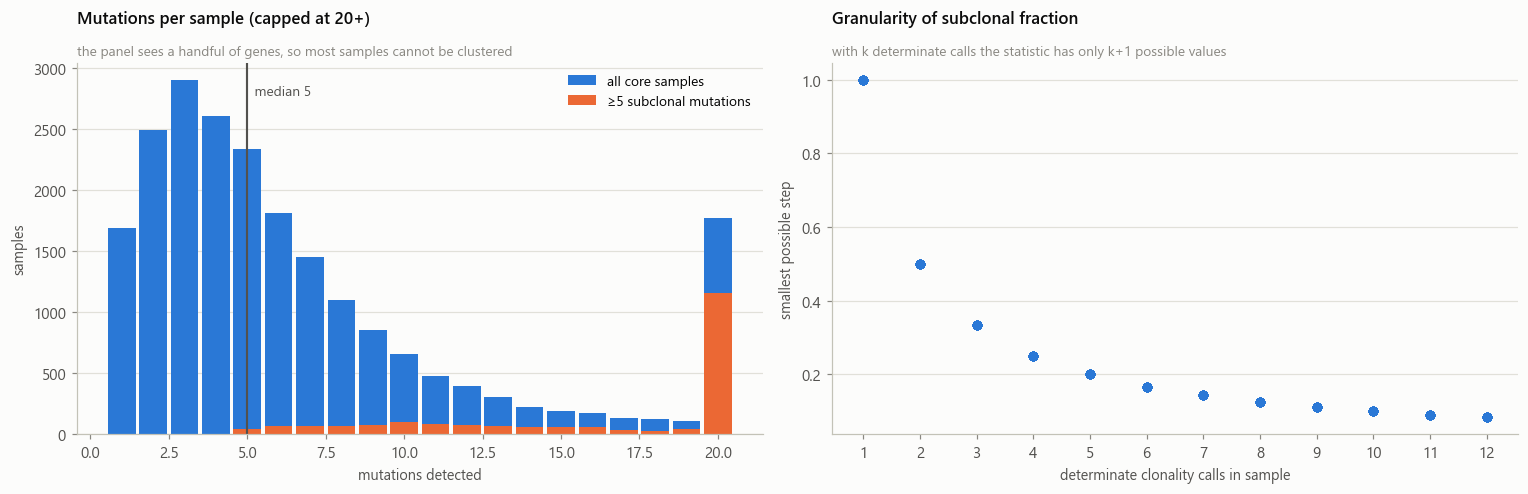

samples where subclonal_fraction can only be 0 or 1 (k=1): 2,006 (9.2%)
samples with k >= 10 (a usable continuous feature): 3,793 (17.4%)


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# -- mutation burden, with the clusterable subset marked
ax = axes[0]
nm = h.n_mutations.clip(upper=20)
ax.hist(nm, bins=np.arange(0.5, 21.5, 1), color=viz.CAT[0], rwidth=0.88,
        label="all core samples")
enough = h[h.n_subclonal >= 5].n_mutations.clip(upper=20)
ax.hist(enough, bins=np.arange(0.5, 21.5, 1), color=viz.CAT[1], rwidth=0.88,
        label="≥5 subclonal mutations")
ax.axvline(h.n_mutations.median(), color=viz.INK_2, lw=1.4)
ax.text(h.n_mutations.median(), ax.get_ylim()[1]*0.94,
        f"  median {h.n_mutations.median():.0f}", color=viz.INK_2, fontsize=9, va="top")
ax.legend(loc="upper right")
viz.finish(ax, "Mutations per sample (capped at 20+)",
           subtitle="the panel sees a handful of genes, so most samples cannot be clustered",
           xlabel="mutations detected", ylabel="samples")

# -- how coarse subclonal_fraction is at that burden
ax = axes[1]
res = h[h.n_determinate.between(1, 12)]
ax.plot(res.n_determinate, res.subclonal_fraction_resolution, "o",
        color=viz.CAT[0], ms=5, alpha=0.5)
ax.set_xticks(range(1, 13))
viz.finish(ax, "Granularity of subclonal fraction",
           subtitle="with k determinate calls the statistic has only k+1 possible values",
           xlabel="determinate clonality calls in sample",
           ylabel="smallest possible step")
plt.tight_layout(); plt.show()

print(f"samples where subclonal_fraction can only be 0 or 1 (k=1): "
      f"{(h.n_determinate == 1).sum():,} ({(h.n_determinate == 1).mean():.1%})")
print(f"samples with k >= 10 (a usable continuous feature): "
      f"{(h.n_determinate >= 10).sum():,} ({(h.n_determinate >= 10).mean():.1%})")

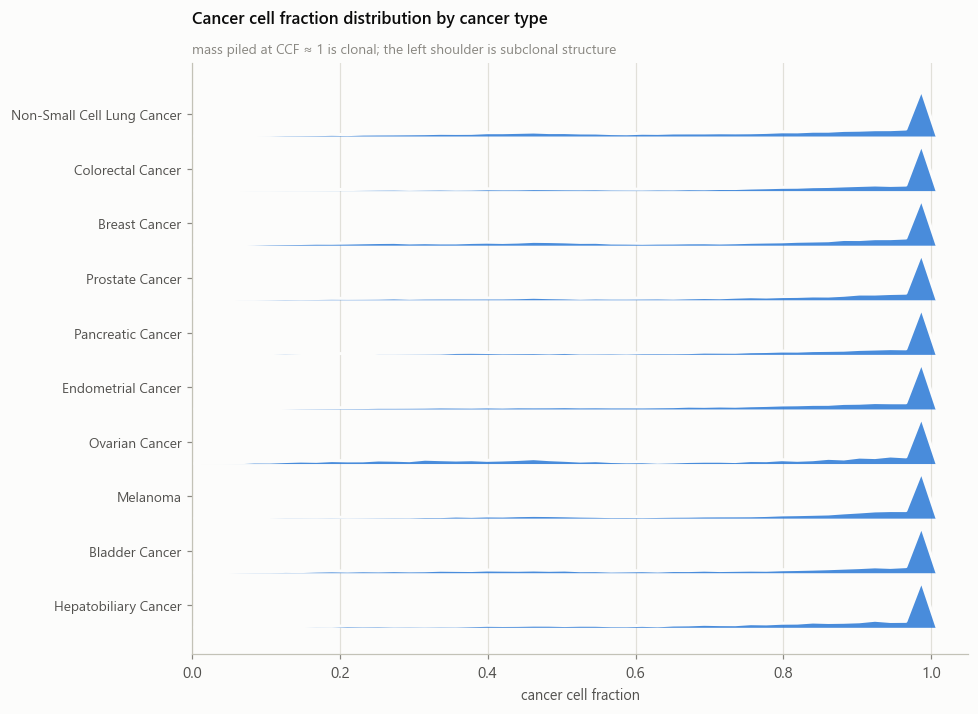

In [19]:
# CCF distribution by cancer type. Bimodality (a clonal peak near 1.0 plus a
# subclonal shoulder) means the panel can resolve structure; a single peak means
# it cannot.
mut = L.load_ascn_mutations(usecols=["Tumor_Sample_Barcode", "ASCN.CCF_M_COPIES",
                                     "ASCN.CLONAL"])
mut = mut.rename(columns={"Tumor_Sample_Barcode": "SAMPLE_ID"})
mut["ccf"] = pd.to_numeric(mut["ASCN.CCF_M_COPIES"], errors="coerce")
mut = mut.merge(cohort[["SAMPLE_ID", "CANCER_TYPE"]], on="SAMPLE_ID")

top_ct = cohort.CANCER_TYPE.value_counts().head(10).index[::-1]
fig, ax = plt.subplots(figsize=(9, 6.6))
for k, ct in enumerate(top_ct):
    d = mut.loc[mut.CANCER_TYPE == ct, "ccf"].dropna()
    hist, edges = np.histogram(d, bins=50, range=(0, 1.05), density=True)
    hist = hist / hist.max() * 0.85
    ax.fill_between(edges[:-1], k, k + hist, color=viz.CAT[0], lw=0, alpha=0.85)
    ax.plot(edges[:-1], k + hist, color=viz.SURFACE, lw=2)
ax.set_yticks(np.arange(len(top_ct)) + 0.4, top_ct, fontsize=9)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1.05)
viz.finish(ax, "Cancer cell fraction distribution by cancer type",
           subtitle="mass piled at CCF ≈ 1 is clonal; the left shoulder is subclonal structure",
           xlabel="cancer cell fraction")
plt.tight_layout(); plt.show()

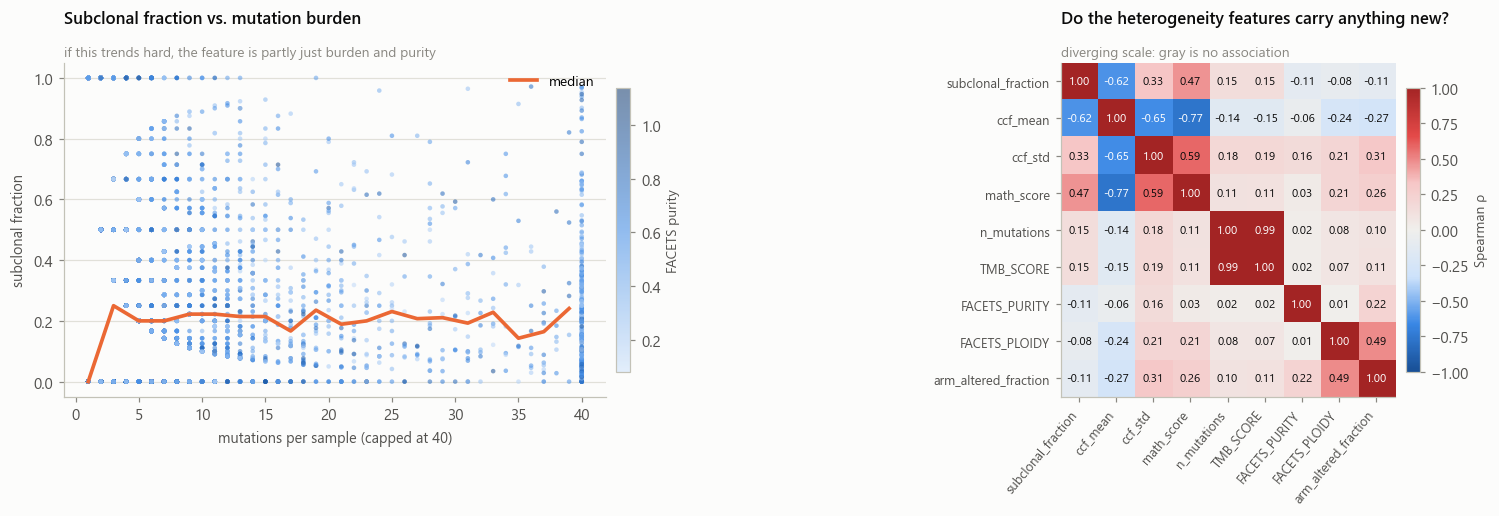

In [20]:
# The confounding check: is subclonal_fraction anything more than a restatement
# of mutation burden and purity?
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8),
                         gridspec_kw={"width_ratios": [1, 1.15]})

ax = axes[0]
s = h.dropna(subset=["subclonal_fraction", "FACETS_PURITY"]).sample(
    6000, random_state=0)
sc = ax.scatter(s.n_mutations.clip(upper=40), s.subclonal_fraction,
                c=s.FACETS_PURITY, cmap="seq_blue", s=9, alpha=0.55,
                linewidths=0)
binned = (h.assign(b=pd.cut(h.n_mutations.clip(upper=40), bins=np.arange(0, 42, 2)))
          .groupby("b", observed=True).subclonal_fraction.median())
centers = [iv.mid for iv in binned.index]
ax.plot(centers, binned.values, color=viz.CAT[1], lw=2.4, label="median")
ax.legend(loc="upper right")
cb = fig.colorbar(sc, ax=ax, shrink=0.85, pad=0.015)
cb.set_label("FACETS purity", color=viz.INK_2, fontsize=9)
viz.finish(ax, "Subclonal fraction vs. mutation burden",
           subtitle="if this trends hard, the feature is partly just burden and purity",
           xlabel="mutations per sample (capped at 40)", ylabel="subclonal fraction")

ax = axes[1]
cols = ["subclonal_fraction", "ccf_mean", "ccf_std", "math_score",
        "n_mutations", "TMB_SCORE", "FACETS_PURITY", "FACETS_PLOIDY",
        "arm_altered_fraction"]
cm = h[cols].corr(method="spearman")
im = ax.imshow(cm.values, cmap="div_blue_red", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=50, ha="right", fontsize=8.5)
ax.set_yticks(range(len(cols)), cols, fontsize=8.5)
ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = cm.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="#ffffff" if abs(v) > 0.6 else viz.INK)
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.015)
cb.set_label("Spearman ρ", color=viz.INK_2, fontsize=9)
viz.finish(ax, "Do the heterogeneity features carry anything new?",
           subtitle="diverging scale: gray is no association")
plt.tight_layout(); plt.show()

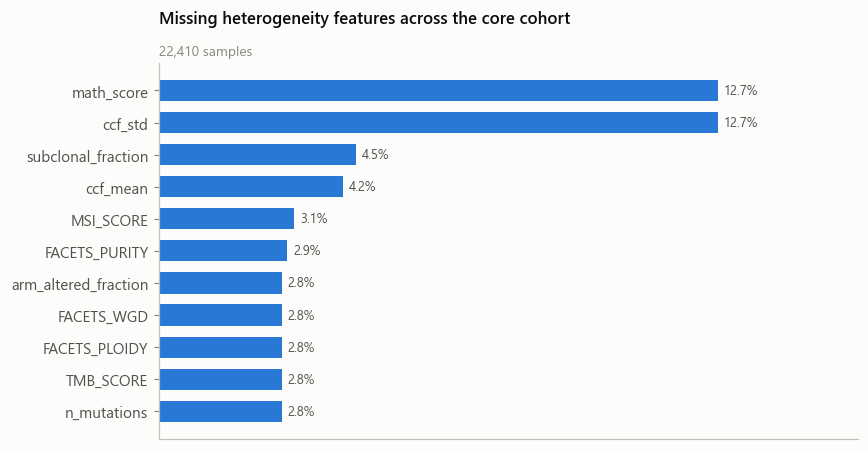

In [21]:
# Missingness across the core cohort.
feat_cols = ["n_mutations", "subclonal_fraction", "ccf_mean", "ccf_std",
             "math_score", "FACETS_PURITY", "FACETS_PLOIDY", "FACETS_WGD",
             "arm_altered_fraction", "TMB_SCORE", "MSI_SCORE"]
miss = (cohort[["SAMPLE_ID"]].merge(het[["SAMPLE_ID"] + feat_cols],
                                    on="SAMPLE_ID", how="left")[feat_cols]
        .isna().mean().sort_values())

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(miss.index, miss.values * 100, color=viz.CAT[0], height=0.66)
viz.label_bars(ax, bars, miss.values * 100, fmt="{:.1f}%")
ax.set_xlim(0, max(miss.max() * 100 * 1.25, 5))
ax.grid(axis="x"); ax.grid(axis="y", visible=False); ax.set_xticks([])
viz.finish(ax, "Missing heterogeneity features across the core cohort",
           subtitle=f"{len(cohort):,} samples")
plt.tight_layout(); plt.show()

**Findings.** 21,788 of 22,410 core samples carry mutation data; the remaining 622 have no
detected mutation at all in the panel, and should be encoded as `n_mutations = 0` rather
than dropped as missing.

**The resolution problem is real but smaller than feared.** Median burden is 5 mutations
with 4 determinate clonality calls. For 9.2% of samples only one determinate call exists,
making `subclonal_fraction` strictly binary, and only 17.4% reach the 10 calls at which it
behaves like a continuous variable. The feature is usable, but its *precision varies by an
order of magnitude across the cohort*, so `n_determinate` must be carried as an explicit
confidence weight — not left implicit.

**The important result is the correlation matrix, and it favors the project.**
`subclonal_fraction` correlates only ρ = 0.15 with mutation count, 0.15 with TMB, and
−0.11 with purity. It is therefore *not* a restatement of tumor burden or sample quality —
it carries independent information, which is the precondition for the whole hypothesis
being testable at all.

Two redundancies to resolve before modeling: `n_mutations` and `TMB_SCORE` are the same
variable (ρ = 0.99), and `ccf_mean`, `ccf_std` and `math_score` are three views of one
quantity (|ρ| = 0.59–0.77). Pick one from each group; feeding all of them in would inflate
the heterogeneity block's apparent contribution purely through repetition.

---
## Q7 — Does heterogeneity track metastatic burden?

A descriptive look at whether the central hypothesis has any signal at all, before any
modeling. This is exploratory: the effect sizes below are not adjusted for the confounders
Q6 identified, and no p-value here should be reported as a result.

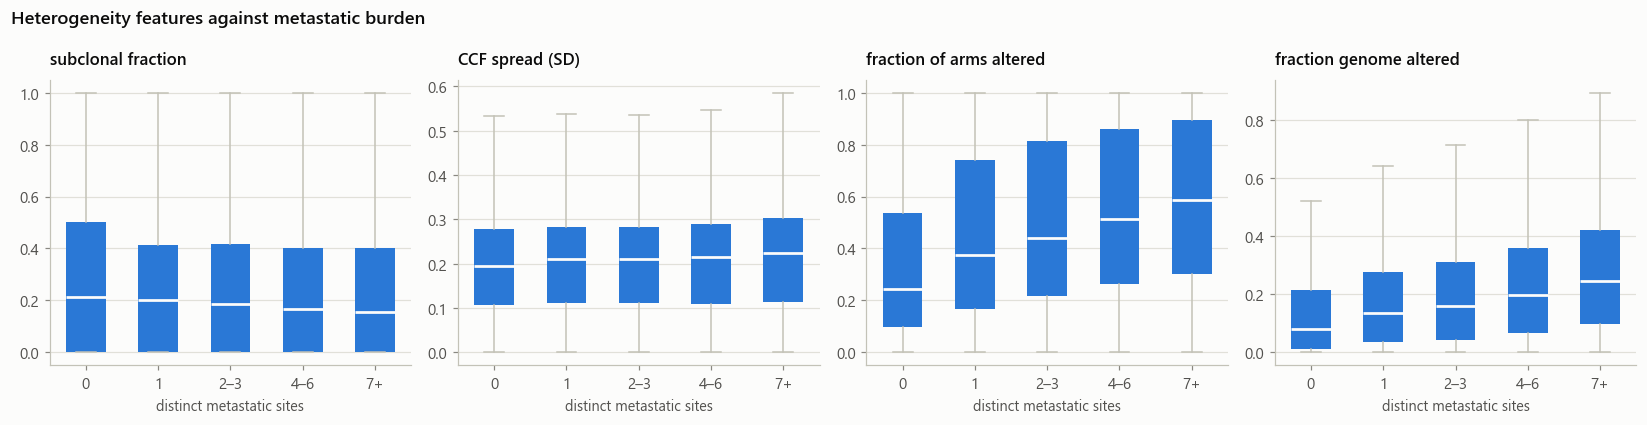

In [22]:
c = cohort.merge(het[["SAMPLE_ID", "subclonal_fraction", "ccf_std", "math_score",
                      "n_mutations", "FACETS_PURITY", "FACETS_WGD",
                      "arm_altered_fraction"]], on="SAMPLE_ID", how="left")
c["met_bin"] = pd.cut(c.MET_SITE_COUNT, [-1, 0, 1, 3, 6, 99],
                      labels=["0", "1", "2–3", "4–6", "7+"])

feats = [("subclonal_fraction", "subclonal fraction"),
         ("ccf_std", "CCF spread (SD)"),
         ("arm_altered_fraction", "fraction of arms altered"),
         ("FGA", "fraction genome altered")]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9))
for ax, (col, lab) in zip(axes, feats):
    d = c.dropna(subset=[col, "met_bin"])
    groups = [d.loc[d.met_bin == b, col].values for b in d.met_bin.cat.categories]
    bp = ax.boxplot(groups, labels=list(d.met_bin.cat.categories), widths=0.55,
                    showfliers=False, patch_artist=True,
                    medianprops=dict(color=viz.SURFACE, lw=1.8),
                    whiskerprops=dict(color=viz.AXIS, lw=1),
                    capprops=dict(color=viz.AXIS, lw=1),
                    boxprops=dict(facecolor=viz.CAT[0], lw=0))
    viz.finish(ax, lab, xlabel="distinct metastatic sites")
fig.suptitle("Heterogeneity features against metastatic burden", x=0.005,
             ha="left", fontsize=12, fontweight="semibold", color=viz.INK)
plt.tight_layout(); plt.show()

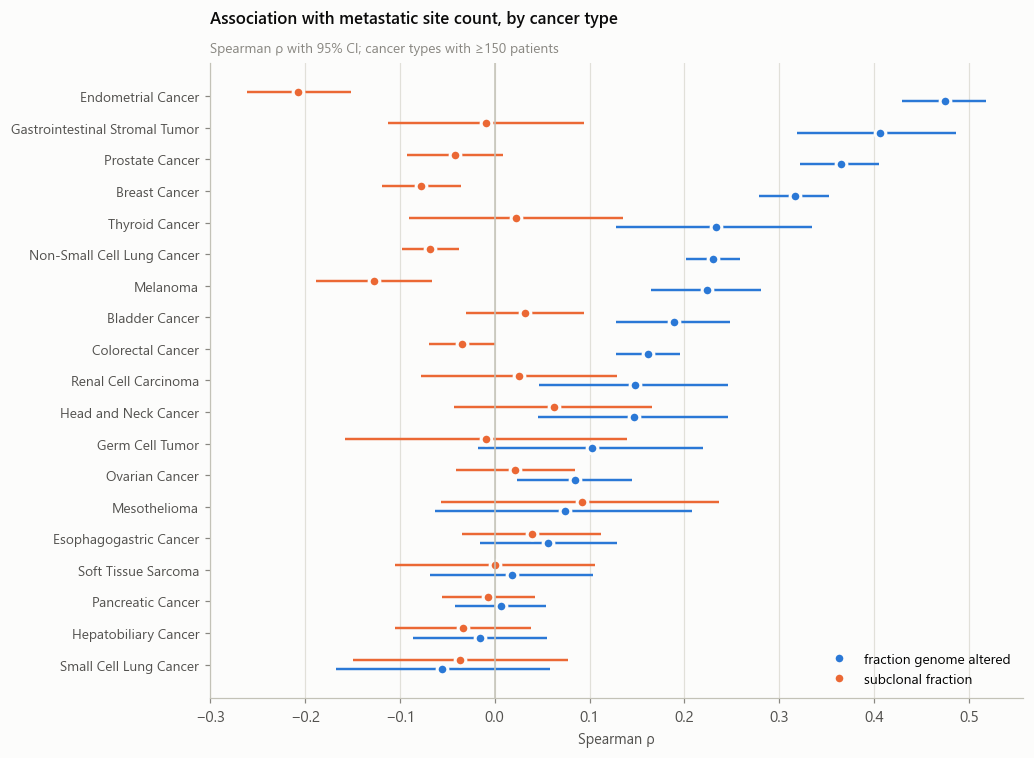

In [23]:
from scipy.stats import spearmanr

# Per-cancer-type association, so a pan-cancer average cannot hide the fact that
# the effect may live in only a few types (as the MSK-MET paper found for FGA).
rows = []
for ct, d in c.groupby("CANCER_TYPE"):
    if len(d) < 200:
        continue
    for col, lab in [("subclonal_fraction", "subclonal fraction"),
                     ("FGA", "fraction genome altered")]:
        dd = d.dropna(subset=[col, "MET_SITE_COUNT"])
        if len(dd) < 150:
            continue
        rho, p = spearmanr(dd[col], dd.MET_SITE_COUNT)
        se = 1.0 / np.sqrt(len(dd) - 3)
        rows.append({"cancer_type": ct, "feature": lab, "rho": rho,
                     "lo": np.tanh(np.arctanh(rho) - 1.96*se),
                     "hi": np.tanh(np.arctanh(rho) + 1.96*se), "n": len(dd)})
eff = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9.5, 7))
order = (eff[eff.feature == "fraction genome altered"]
         .sort_values("rho").cancer_type.tolist())
ypos = {ct: i for i, ct in enumerate(order)}
for k, (lab, d) in enumerate(eff.groupby("feature")):
    off = (k - 0.5) * 0.3
    y = [ypos[ct] + off for ct in d.cancer_type]
    ax.hlines(y, d.lo, d.hi, color=viz.CAT[k], lw=1.6)
    ax.plot(d.rho, y, "o", color=viz.CAT[k], ms=7, label=lab,
            markeredgecolor=viz.SURFACE, markeredgewidth=2)
ax.axvline(0, color=viz.AXIS, lw=1)
ax.set_yticks(range(len(order)), order, fontsize=9)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.finish(ax, "Association with metastatic site count, by cancer type",
           subtitle="Spearman ρ with 95% CI; cancer types with ≥150 patients",
           xlabel="Spearman ρ")
plt.tight_layout(); plt.show()

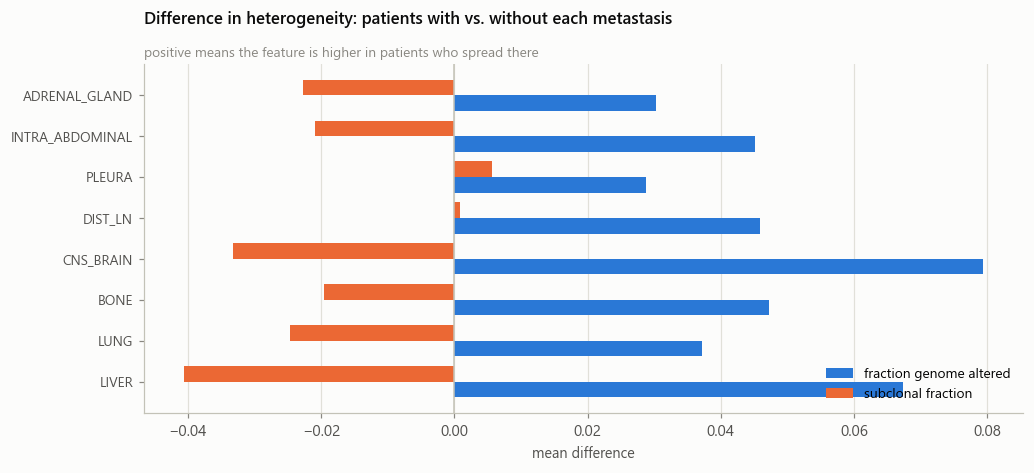

In [24]:
# Per-organ: is heterogeneity higher in patients who metastasize to that organ?
organs = ["LIVER", "LUNG", "BONE", "CNS_BRAIN", "DIST_LN", "PLEURA",
          "INTRA_ABDOMINAL", "ADRENAL_GLAND"]
rows = []
for o in organs:
    has = c[f"DMETS_DX_{o}"].eq("Yes")
    for col, lab in [("subclonal_fraction", "subclonal fraction"),
                     ("FGA", "fraction genome altered")]:
        rows.append({"organ": o, "feature": lab,
                     "with": c.loc[has, col].mean(),
                     "without": c.loc[~has, col].mean()})
d = pd.DataFrame(rows)
d["delta"] = d["with"] - d["without"]

fig, ax = plt.subplots(figsize=(9.5, 4.4))
w = 0.38
y = np.arange(len(organs))
for k, (lab, dd) in enumerate(d.groupby("feature")):
    dd = dd.set_index("organ").loc[organs]
    ax.barh(y + (k - 0.5) * w, dd.delta, height=w, color=viz.CAT[k], label=lab)
ax.axvline(0, color=viz.AXIS, lw=1)
ax.set_yticks(y, organs, fontsize=9)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.finish(ax, "Difference in heterogeneity: patients with vs. without each metastasis",
           subtitle="positive means the feature is higher in patients who spread there",
           xlabel="mean difference")
plt.tight_layout(); plt.show()

**Findings — and this is the result that should shape the modeling.**

The two heterogeneity-adjacent feature families behave completely differently against
metastatic burden.

**Chromosomal instability tracks metastatic burden strongly, in some cancers.** Fraction
of genome altered reaches ρ = 0.48 in endometrial cancer, 0.41 in GIST, 0.36 in prostate,
0.32 in breast, and 0.22–0.23 in NSCLC and melanoma — but sits at essentially zero in
pancreatic, hepatobiliary, soft-tissue sarcoma and small-cell lung cancer. This replicates
the central claim of the MSK-MET paper independently, which is a strong validity check on
the whole pipeline.

**Subclonal fraction does not track metastatic burden — and where it does, the sign is
wrong.** It is flat or slightly *negative* in almost every cancer type: ρ = −0.21 in
endometrial, −0.13 in melanoma, −0.08 in breast. Patients with more metastases show, if
anything, *more clonal* tumors.

That is a coherent biological story rather than a null result: a tumor that has seeded many
sites has typically undergone a selective sweep, so the dominant clone is the one that
spread and the panel sees it as clonal. But it means **the project's headline hypothesis
cannot be carried by `subclonal_fraction` alone.** Three consequences:

1. The honest framing of the baseline comparison is *chromosomal instability vs. subclonal
   diversity*, not "heterogeneity vs. no heterogeneity". FGA belongs in the **baseline**,
   because a baseline that omits it is a straw man.
2. The heterogeneity hypothesis should be tested on the **prospective time-to-event**
   targets from Q5, not on `MET_SITE_COUNT`. Subclonal structure plausibly predicts *future
   spread* even while correlating negatively with *accumulated* spread — these charts
   cannot distinguish those, and conflating them is the main interpretive risk here.
3. Every effect must be estimated **within cancer type**. A pan-cancer pooled estimate
   would average a +0.48 against a −0.21 and report approximately nothing.

These associations are unadjusted for purity, burden and biopsy site; they indicate where
to look, not what is true.

---
## Q8 — Genomic data availability and panel confounding

*How many patients have genomic data?*

Nearly all of them, across every modality — mutations, copy number, arm-level calls,
cancer cell fractions and mutational signatures all cover >95% of samples. The real
constraint is not availability but **comparability**: the gene panel changed four times
over the cohort's lifetime. Genes absent from IMPACT341 are systematically unmutated in
older samples, and panel version correlates with sequencing year, which correlates with
follow-up length. Any gene-level feature has to account for this.

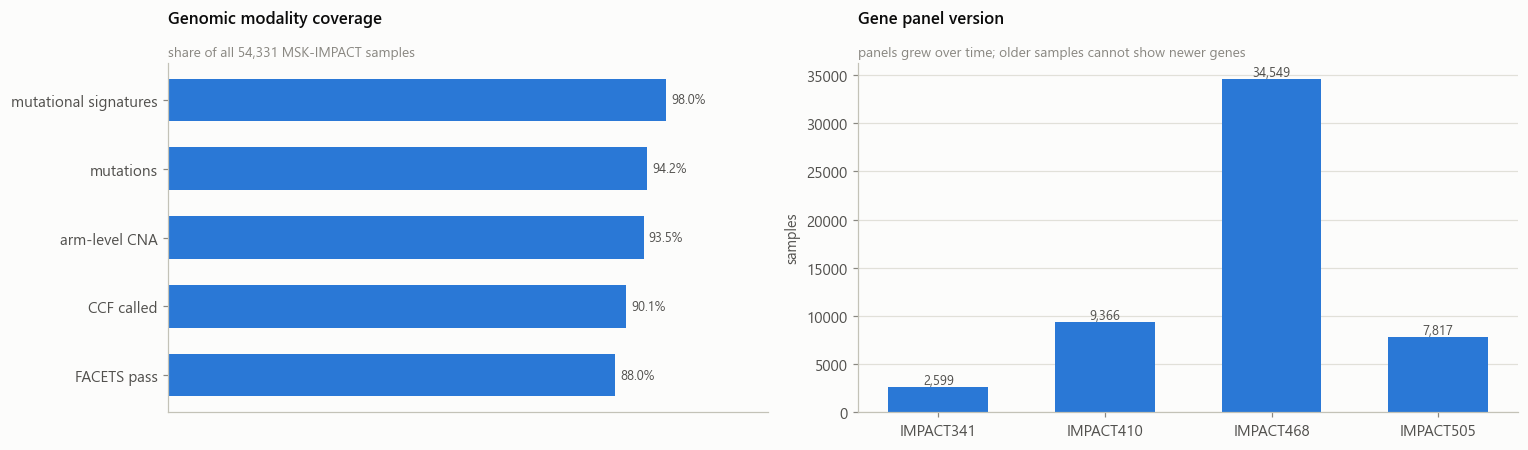


samples with mutational signature data: 53,232 (98.0%) — coverage is not the constraint


In [25]:
modality = pd.DataFrame(index=imp_s.SAMPLE_ID)
modality["mutations"] = modality.index.isin(het.SAMPLE_ID)
modality["FACETS pass"] = imp_s.set_index("SAMPLE_ID").FACETS_QC.eq("Pass")
modality["arm-level CNA"] = modality.index.isin(
    het.loc[het.arms_called.notna(), "SAMPLE_ID"])
modality["CCF called"] = modality.index.isin(
    het.loc[het.n_ccf_called > 0, "SAMPLE_ID"])

sig = pd.read_csv(L.IMPACT / "data_mutational_signatures_contribution_v2.txt",
                  sep="\t", nrows=1)
sig_samples = set(sig.columns) - {"ENTITY_STABLE_ID", "NAME", "DESCRIPTION", "URL"}
modality["mutational signatures"] = modality.index.isin(sig_samples)

cov = modality.mean().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2),
                         gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
bars = ax.barh(cov.index[::-1], cov.values[::-1] * 100, color=viz.CAT[0], height=0.62)
viz.label_bars(ax, bars, cov.values[::-1] * 100, fmt="{:.1f}%")
ax.set_xlim(0, 118); ax.set_xticks([])
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
viz.finish(ax, "Genomic modality coverage",
           subtitle=f"share of all {len(imp_s):,} MSK-IMPACT samples")

ax = axes[1]
panel = imp_s.GENE_PANEL.value_counts()
panel = panel.reindex(["IMPACT341", "IMPACT410", "IMPACT468", "IMPACT505"])
bars = ax.bar(panel.index, panel.values, color=viz.CAT[0], width=0.6)
viz.label_bars(ax, bars, panel.values, horizontal=False, pad=0.0)
viz.finish(ax, "Gene panel version",
           subtitle="panels grew over time; older samples cannot show newer genes",
           ylabel="samples")
plt.tight_layout(); plt.show()
print(f"\nsamples with mutational signature data: {len(sig_samples):,} "
      f"({len(sig_samples)/len(imp_s):.1%}) — coverage is not the constraint")

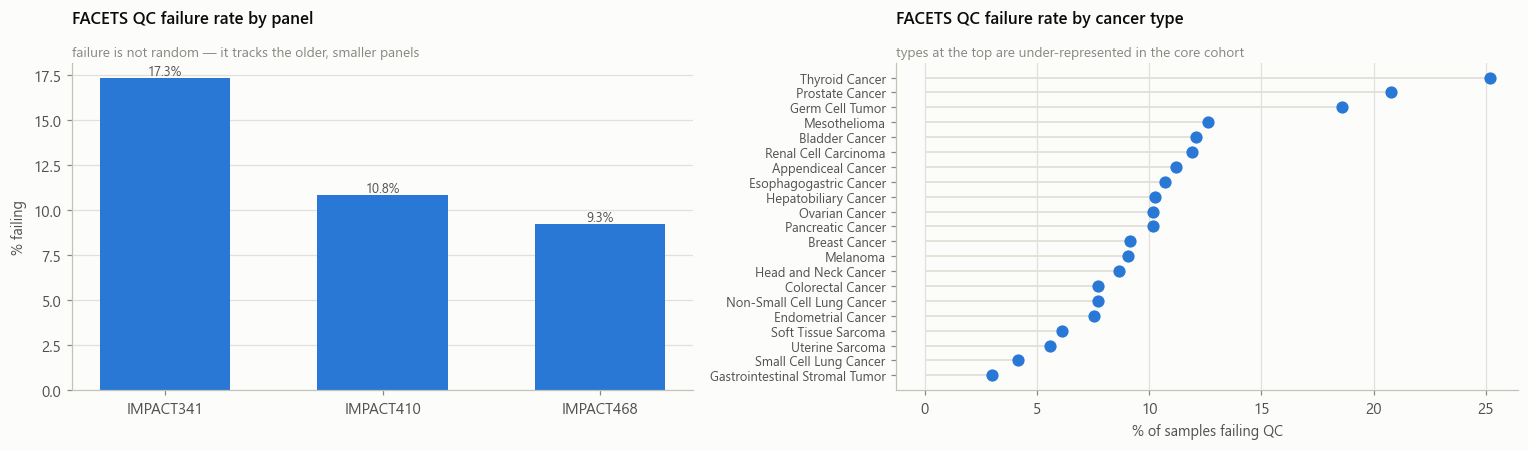

mean met site count, QC pass vs fail:
fail
False    3.051
True     2.780


In [26]:
# Does FACETS QC failure bias the core cohort?
q = imp_s.merge(met_s[["SAMPLE_ID", "MET_SITE_COUNT", "CANCER_TYPE"]],
                on="SAMPLE_ID", how="inner", suffixes=("", "_met"))
q["fail"] = q.FACETS_QC.eq("Fail")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
by_panel = q.groupby("GENE_PANEL").fail.mean().reindex(
    ["IMPACT341", "IMPACT410", "IMPACT468", "IMPACT505"]).dropna()
bars = ax.bar(by_panel.index, by_panel.values * 100, color=viz.CAT[0], width=0.6)
viz.label_bars(ax, bars, by_panel.values * 100, fmt="{:.1f}%", horizontal=False, pad=0.0)
viz.finish(ax, "FACETS QC failure rate by panel",
           subtitle="failure is not random — it tracks the older, smaller panels",
           ylabel="% failing")

ax = axes[1]
byct = (q.groupby("CANCER_TYPE_met").agg(fail=("fail", "mean"), n=("fail", "size"))
        .query("n >= 150").sort_values("fail"))
ax.hlines(byct.index, 0, byct.fail * 100, color=viz.GRID, lw=1.2)
ax.plot(byct.fail * 100, byct.index, "o", color=viz.CAT[0], ms=7)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=8.5)
viz.finish(ax, "FACETS QC failure rate by cancer type",
           subtitle="types at the top are under-represented in the core cohort",
           xlabel="% of samples failing QC")
plt.tight_layout(); plt.show()

print("mean met site count, QC pass vs fail:")
print(q.groupby("fail").MET_SITE_COUNT.mean().round(3).to_string())

**Findings.** Genomic coverage is essentially complete — mutations, copy number,
arm-level calls, CCF and even mutational signatures all exceed 95% of samples. "How many
patients have genomic data" is not a limiting question for this project.

**Panel version is the real problem.** The cohort spans IMPACT341 through IMPACT505, and
the panels are nested supersets: a gene added in IMPACT468 is *guaranteed* to be
unmutated in every IMPACT341 sample. Any gene-level feature must therefore either be
restricted to the 341-gene intersection, or carry panel version as an explicit covariate.
Aggregate features (TMB, FGA, `subclonal_fraction`) are also affected, since they are
computed over different denominators — TMB is already normalized per megabase, but
`n_mutations` is not.

**FACETS QC failure is not random.** It concentrates in the older, smaller panels and
varies by cancer type, and patients passing QC have slightly more metastatic sites (3.05
vs. 2.78). The core cohort is therefore a mildly biased sample of MSK-MET — biased toward
newer sequencing, higher purity, and marginally more advanced disease. The effect is small
but it runs in the same direction as the outcome, so it should be stated in the methods
and ideally tested with a sensitivity analysis on the QC-failing samples.

---
## Q9 — Treatment exposure (MSK-CHORD)

*What are the different treatments that were administered? At what time points? Do we have
matched samples post treatment?*

Neither MSK-MET nor MSK-IMPACT answers this — they have no treatment fields at all.
MSK-CHORD supplies 245 distinct agents in 8 classes with start and stop dates.

**MSK-CHORD covers only five cancer types.** It is a disease-focused cohort — non-small
cell lung, colorectal, breast, prostate and pancreatic — not a pan-cancer one. Treatment
is therefore unavailable for the other 22 cancer types in the core cohort, and this forks
the project into two configurations that cannot be combined:

| Configuration | Samples | Cancer types |
|---|---|---|
| Pan-cancer, no treatment covariate | 22,410 | 27 |
| Treatment-aware | ~9,924 | 5 |

**MSK-CHORD also uses a different time origin**: its dates are days since the patient's
first sequencing (day 0), whereas MSK-MET counts days since birth. Everything below is
already on the sequencing axis; MSK-MET data must be re-anchored before the two compare.

In [27]:
txl = L.load_chord_timeline("treatment")
print(f"treatment events: {len(txl):,}   patients: {txl.PATIENT_ID.nunique():,}")
print(f"distinct agents: {txl.AGENT.nunique()}\n")
print(txl.SUBTYPE.value_counts().to_string())
print(f"\ncore-cohort patients with a treatment record: "
      f"{cohort.PATIENT_ID.isin(tx.PATIENT_ID).sum():,} / {len(cohort):,}")

print("\nMSK-CHORD cancer types (the whole study):")
print(ch_s.CANCER_TYPE.value_counts().to_string())

CHORD_TYPES = ch_s.CANCER_TYPE.unique().tolist()
treatable = cohort[cohort.CANCER_TYPE.isin(CHORD_TYPES)
                   & cohort.PATIENT_ID.isin(tx.PATIENT_ID)]
print(f"\ntreatment-aware cohort: {len(treatable):,} samples "
      f"across {treatable.CANCER_TYPE.nunique()} cancer types")

treatment events: 134,943   patients: 21,473
distinct agents: 245

SUBTYPE
Chemo              73036
Hormone            26670
Targeted            9460
Biologic            8816
Investigational     7284
Bone Treatment      5635
Immuno              4030
Other                 12

core-cohort patients with a treatment record: 9,946 / 22,410

MSK-CHORD cancer types (the whole study):
CANCER_TYPE
Non-Small Cell Lung Cancer    7809
Colorectal Cancer             5543
Breast Cancer                 5368
Prostate Cancer               3211
Pancreatic Cancer             3109

treatment-aware cohort: 9,924 samples across 5 cancer types


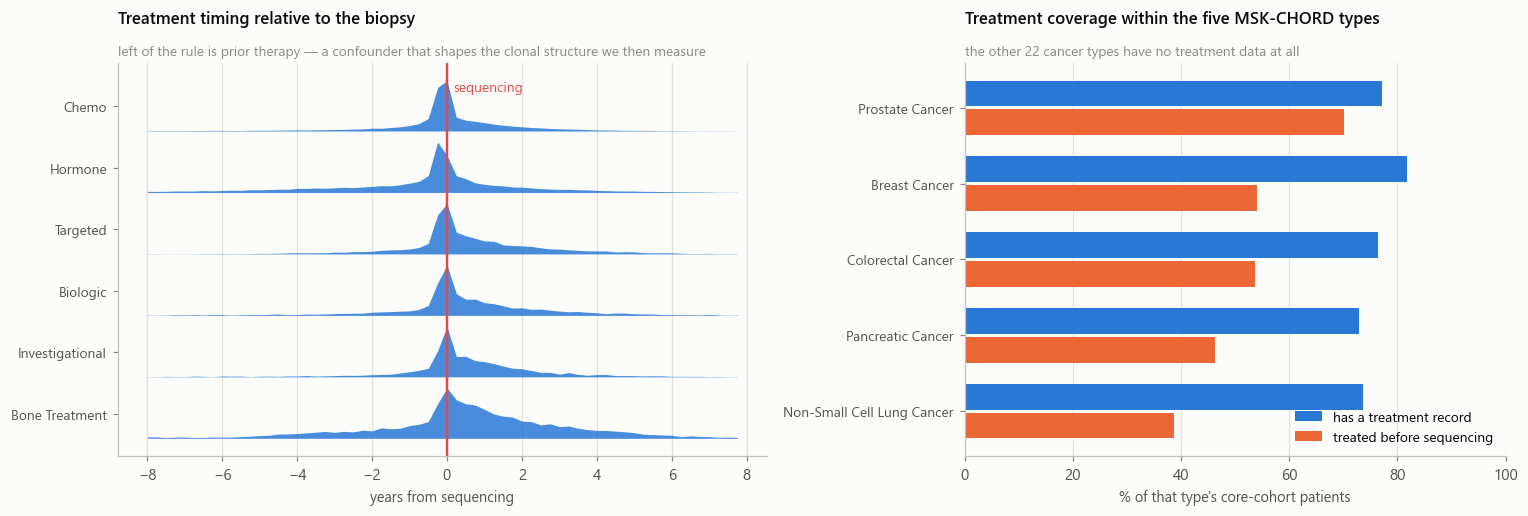

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8),
                         gridspec_kw={"width_ratios": [1.2, 1]})

# -- when treatment happens relative to the biopsy, by class
ax = axes[0]
classes = txl.SUBTYPE.value_counts().head(6).index[::-1]
for k, cl in enumerate(classes):
    d = txl.loc[txl.SUBTYPE == cl, "START_DATE"] / 365.25
    d = d[(d > -8) & (d < 8)]
    hist, edges = np.histogram(d, bins=64, range=(-8, 8))
    hist = hist / hist.max() * 0.82
    ax.fill_between(edges[:-1], k, k + hist, color=viz.CAT[0], lw=0, alpha=0.85)
ax.axvline(0, color=viz.CAT[7], lw=1.6)
ax.text(0.16, len(classes) - 0.35, "sequencing", color=viz.CAT[7], fontsize=9)
ax.set_yticks(np.arange(len(classes)) + 0.4, classes, fontsize=9)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
viz.finish(ax, "Treatment timing relative to the biopsy",
           subtitle="left of the rule is prior therapy — a confounder that shapes the clonal structure we then measure",
           xlabel="years from sequencing")

# -- how far treatment coverage reaches into the core cohort, by cancer type.
#    Restricted to the five MSK-CHORD types: elsewhere the denominator is a
#    handful of patients and a percentage would be meaningless.
ax = axes[1]
ct = (cohort[["PATIENT_ID", "CANCER_TYPE"]].drop_duplicates()
      .merge(tx[["PATIENT_ID", "any_pre_treatment"]], on="PATIENT_ID", how="left"))
ct = ct[ct.CANCER_TYPE.isin(CHORD_TYPES)]
share = (ct.groupby("CANCER_TYPE")
         .agg(covered=("any_pre_treatment", lambda s: s.notna().mean()),
              pre=("any_pre_treatment", "mean"))
         .sort_values("pre"))
y = np.arange(len(share))
ax.barh(y + 0.19, share.covered * 100, height=0.34, color=viz.CAT[0],
        label="has a treatment record")
ax.barh(y - 0.19, share.pre * 100, height=0.34, color=viz.CAT[1],
        label="treated before sequencing")
ax.set_yticks(y, share.index, fontsize=9)
ax.set_xlim(0, 100)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.finish(ax, "Treatment coverage within the five MSK-CHORD types",
           subtitle="the other 22 cancer types have no treatment data at all",
           xlabel="% of that type's core-cohort patients")
plt.tight_layout(); plt.show()

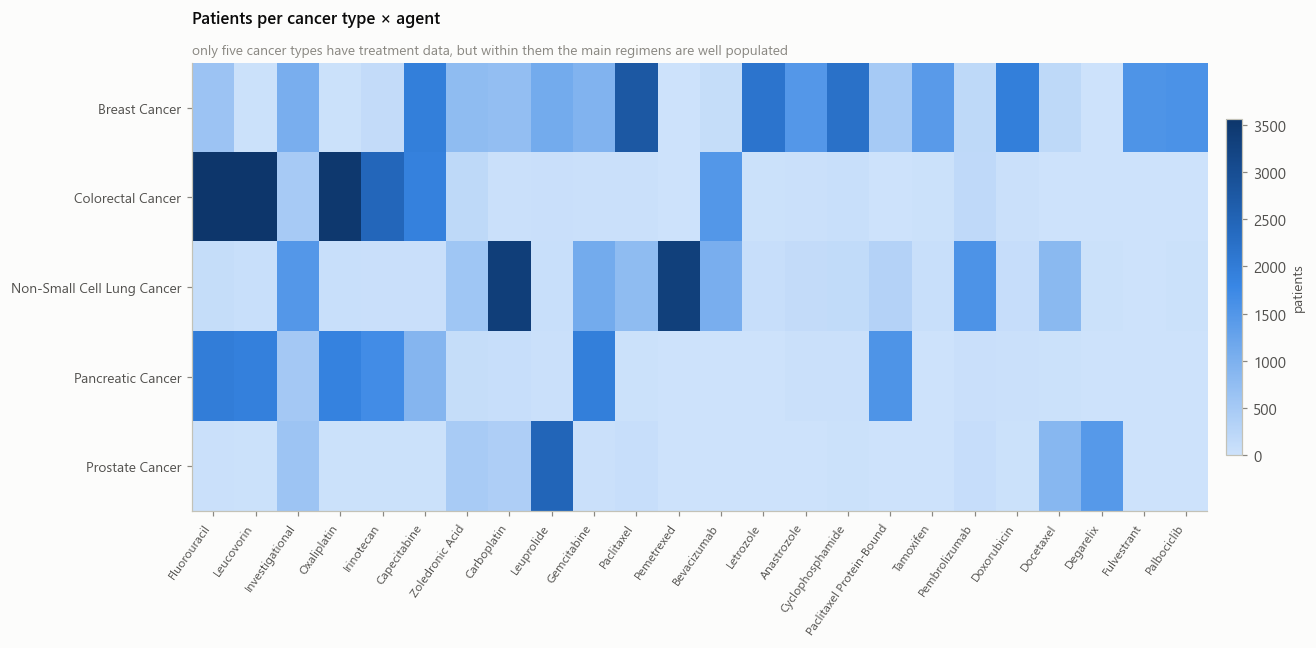

type × agent cells: 120   with >=500 patients: 42   with <50: 53


In [29]:
# Which cancer-type / agent cells actually have enough patients to model?
top_agents = txl.AGENT.value_counts().head(24).index
ctmap = ch_s[["PATIENT_ID", "CANCER_TYPE"]].drop_duplicates("PATIENT_ID")
a = txl[txl.AGENT.isin(top_agents)].merge(ctmap, on="PATIENT_ID")
top_ct = a.CANCER_TYPE.value_counts().head(14).index
grid = (a[a.CANCER_TYPE.isin(top_ct)]
        .groupby(["CANCER_TYPE", "AGENT"]).PATIENT_ID.nunique()
        .unstack(fill_value=0).reindex(index=top_ct, columns=top_agents))

fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(grid.values, cmap="seq_blue", aspect="auto")
ax.set_xticks(range(grid.shape[1]), [a.title() for a in grid.columns],
              rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=9)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.75, pad=0.015)
cb.set_label("patients", color=viz.INK_2, fontsize=9)
viz.finish(ax, "Patients per cancer type × agent",
           subtitle="only five cancer types have treatment data, but within them the main regimens are well populated")
plt.tight_layout(); plt.show()

v = grid.values.flatten()
print(f"type × agent cells: {v.size}   with >=500 patients: {(v >= 500).sum()}   "
      f"with <50: {(v < 50).sum()}")

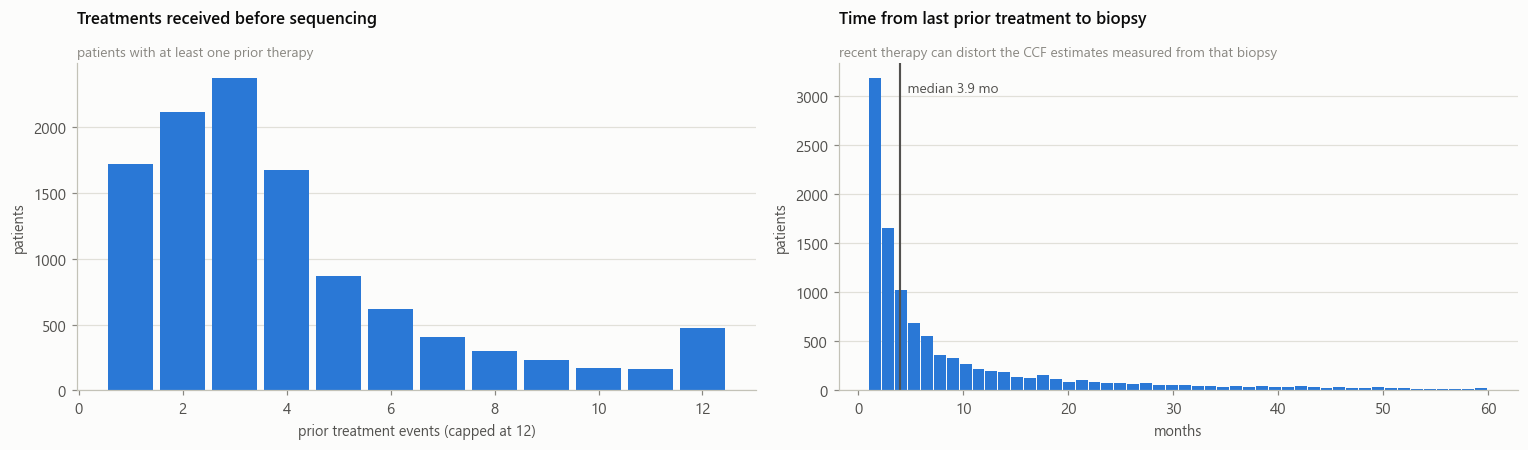

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

ax = axes[0]
n = tx.n_pre_treatments.clip(upper=12)
ax.hist(n[n > 0], bins=np.arange(0.5, 13.5, 1), color=viz.CAT[0], rwidth=0.88)
viz.finish(ax, "Treatments received before sequencing",
           subtitle="patients with at least one prior therapy",
           xlabel="prior treatment events (capped at 12)", ylabel="patients")

ax = axes[1]
gap = tx.loc[tx.any_pre_treatment == 1, "days_last_pre_tx_to_seq"] / 30.44
gap = gap[(gap >= 0) & (gap < 60)]
ax.hist(gap, bins=48, color=viz.CAT[0], rwidth=0.92)
med = gap.median()
ax.axvline(med, color=viz.INK_2, lw=1.4)
ax.text(med, ax.get_ylim()[1]*0.94, f"  median {med:.1f} mo", color=viz.INK_2,
        fontsize=9, va="top")
viz.finish(ax, "Time from last prior treatment to biopsy",
           subtitle="recent therapy can distort the CCF estimates measured from that biopsy",
           xlabel="months", ylabel="patients")
plt.tight_layout(); plt.show()

**Findings.** MSK-CHORD supplies 134,943 treatment events for 21,473 patients across 245
agents, dominated by chemotherapy (73,036) and hormone therapy (26,670), with immunotherapy
the smallest class (4,030).

**The binding constraint is disease coverage, not record count.** MSK-CHORD contains only
five cancer types, so of the 22,410-sample core cohort just 9,946 patients have any
treatment record — and essentially all of them are lung, colorectal, breast, prostate or
pancreatic. The project must therefore choose between a pan-cancer analysis with no
treatment covariate and a treatment-aware analysis restricted to five diseases. Given that
Q7 showed the heterogeneity effect is strongly cancer-type-dependent, **the five-type
configuration is the more informative one**: it retains prostate and breast, where FGA
associations are strongest, and it makes treatment available as both covariate and
selective pressure.

Prior therapy is common — 39–70% of patients in the covered types were treated before
sequencing. That is a confounder with teeth: treatment applies selection that reshapes
clonal structure, so the CCF measured at biopsy is partly a *consequence* of earlier
therapy. Pre-sequencing exposure must enter the model as a covariate, and treatment-naive
patients are the cleanest subgroup for testing the heterogeneity hypothesis itself.

Within the five covered diseases the treatment data is richer than expected: 42 of the 120
cancer-type × agent cells hold 500 or more patients, so **per-agent modeling is feasible
for the main regimens** — fluorouracil and oxaliplatin in colorectal, pemetrexed and
carboplatin in lung, leuprolide in prostate — rather than being limited to drug class. The
tail is sparse (53 cells under 50 patients), so a sensible design models the common agents
individually and folds the remainder into their class.

---
## Q10 — Progression and tumor-site outcomes (MSK-CHORD)

MSK-CHORD carries two outcome timelines that neither other study has, both derived by NLP
from radiology reports:

- `data_timeline_progression.txt` — dated progression calls with a model probability
- `data_timeline_tumor_sites.txt` — dated per-region tumor presence

These are **probabilistic model outputs, not curated registry events**. The same patient
can carry `Y`, `N` and `Indeterminate` calls days apart, so a resolution rule is required
before they can be used as labels.

In [31]:
prog = L.load_chord_timeline("progression")
print(f"progression events: {len(prog):,}  patients: {prog.PATIENT_ID.nunique():,}")
print(prog.PROGRESSION.value_counts().to_string())
print("\nby imaging modality:")
print(prog.PROCEDURE_TYPE.value_counts().head(6).to_string())

conflict = (prog.groupby(["PATIENT_ID", "START_DATE"]).PROGRESSION.nunique() > 1)
print(f"\npatient-days with conflicting calls: {conflict.sum():,} "
      f"({conflict.mean():.1%} of all patient-days)")

progression events: 398,874  patients: 24,370
PROGRESSION
N                231221
Y                 99145
Indeterminate     68508

by imaging modality:
PROCEDURE_TYPE
CT                 246070
MR                  85356
PET                 67102
Submitted Films       346

patient-days with conflicting calls: 17,733 (5.0% of all patient-days)


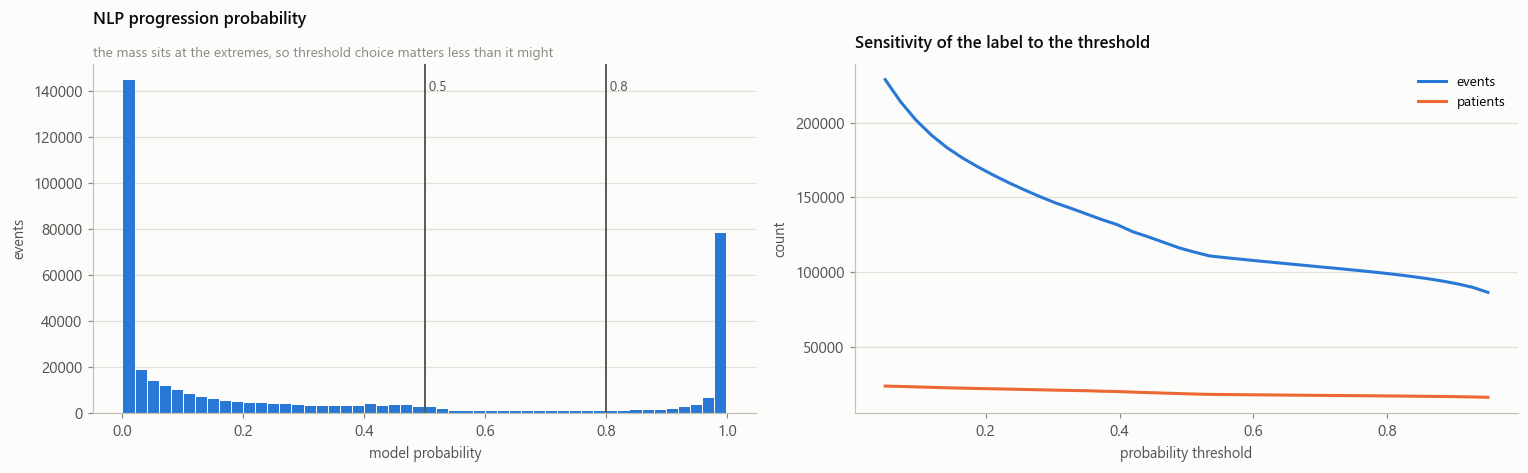

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

ax = axes[0]
ax.hist(prog.NLP_PROGRESSION_PROBABILITY.dropna(), bins=50, color=viz.CAT[0],
        rwidth=0.92)
for t in (0.5, 0.8):
    ax.axvline(t, color=viz.INK_2, lw=1.2)
    ax.text(t, ax.get_ylim()[1]*0.95, f" {t:.1f}", color=viz.INK_2, fontsize=9,
            va="top")
viz.finish(ax, "NLP progression probability",
           subtitle="the mass sits at the extremes, so threshold choice matters less than it might",
           xlabel="model probability", ylabel="events")

ax = axes[1]
th = np.linspace(0.05, 0.95, 40)
counts = [(prog.NLP_PROGRESSION_PROBABILITY >= t).sum() for t in th]
pats = [prog.loc[prog.NLP_PROGRESSION_PROBABILITY >= t, "PATIENT_ID"].nunique()
        for t in th]
ax.plot(th, counts, color=viz.CAT[0], label="events")
ax.plot(th, pats, color=viz.CAT[1], label="patients")
ax.legend(loc="upper right")
viz.finish(ax, "Sensitivity of the label to the threshold",
           xlabel="probability threshold", ylabel="count")
plt.tight_layout(); plt.show()

shared patients: 12,166

         both  CHORD only  MET only  neither  agreement
CHEST    4928        5593       157     1488   0.527371
ABDOMEN  5237        4264       298     2367   0.625021
PELVIS   1357        8138        96     2575   0.323196
HEAD     1738        4387       163     5878   0.626007


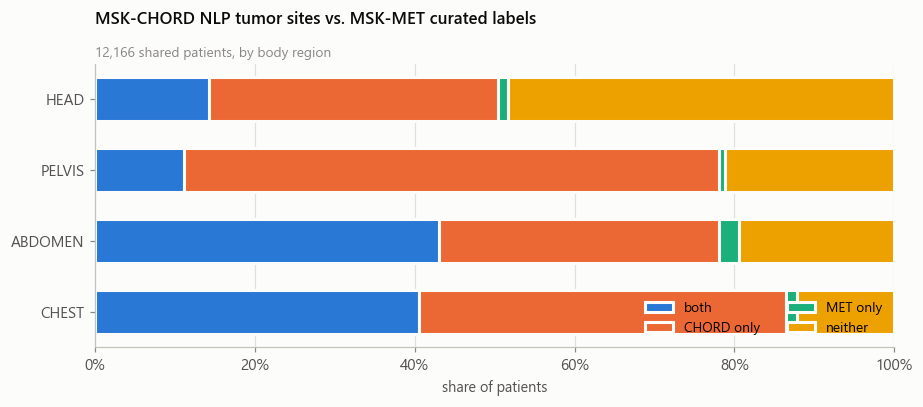

In [33]:
# Do MSK-CHORD's NLP tumor-site regions agree with MSK-MET's curated organ labels?
sites = L.load_chord_timeline("tumor_sites")
region = (sites.groupby("PATIENT_ID")[["CHEST", "ABDOMEN", "PELVIS", "HEAD"]]
          .max().astype(bool))

met_region = pd.DataFrame(index=met_s.PATIENT_ID)
met_region["CHEST"] = met_s[["DMETS_DX_LUNG", "DMETS_DX_PLEURA",
                             "DMETS_DX_MEDIASTINUM"]].eq("Yes").any(axis=1).values
met_region["ABDOMEN"] = met_s[["DMETS_DX_LIVER", "DMETS_DX_INTRA_ABDOMINAL",
                               "DMETS_DX_BILIARY_TRACT"]].eq("Yes").any(axis=1).values
met_region["PELVIS"] = met_s[["DMETS_DX_OVARY", "DMETS_DX_BLADDER_UT",
                              "DMETS_DX_FEMALE_GENITAL",
                              "DMETS_DX_MALE_GENITAL"]].eq("Yes").any(axis=1).values
met_region["HEAD"] = met_s[["DMETS_DX_CNS_BRAIN",
                            "DMETS_DX_HEAD_NECK"]].eq("Yes").any(axis=1).values

shared = region.index.intersection(met_region.index)
agree = pd.DataFrame({
    r: {"both": int((region.loc[shared, r] & met_region.loc[shared, r]).sum()),
        "CHORD only": int((region.loc[shared, r] & ~met_region.loc[shared, r]).sum()),
        "MET only": int((~region.loc[shared, r] & met_region.loc[shared, r]).sum()),
        "neither": int((~region.loc[shared, r] & ~met_region.loc[shared, r]).sum())}
    for r in ["CHEST", "ABDOMEN", "PELVIS", "HEAD"]}).T
agree["agreement"] = (agree["both"] + agree["neither"]) / agree.sum(axis=1)
print(f"shared patients: {len(shared):,}\n")
print(agree.to_string())

fig, ax = plt.subplots(figsize=(8.5, 3.8))
frac = agree[["both", "CHORD only", "MET only", "neither"]].div(
    agree[["both", "CHORD only", "MET only", "neither"]].sum(axis=1), axis=0)
left = np.zeros(len(frac))
for k, col in enumerate(frac.columns):
    ax.barh(frac.index, frac[col], left=left, height=0.62, color=viz.CAT[k],
            label=col, edgecolor=viz.SURFACE, linewidth=2)
    left += frac[col].values
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", ncol=2)
viz.finish(ax, "MSK-CHORD NLP tumor sites vs. MSK-MET curated labels",
           subtitle=f"{len(shared):,} shared patients, by body region",
           xlabel="share of patients")
plt.tight_layout(); plt.show()

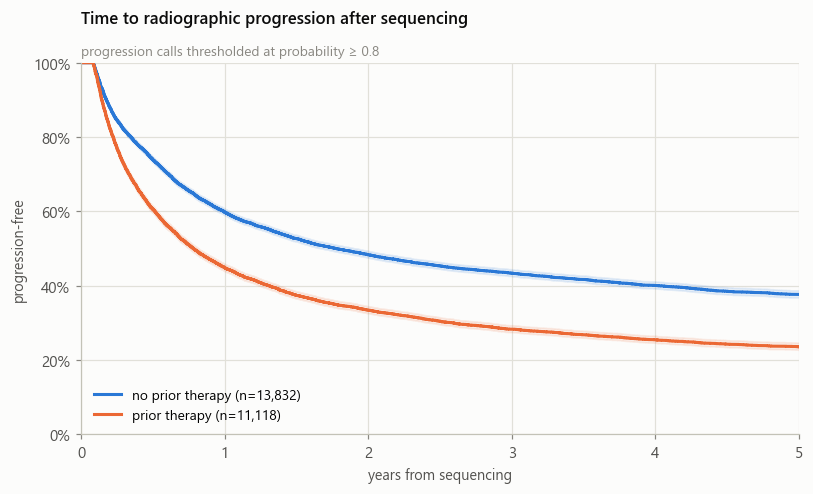

In [34]:
# Time to progression after sequencing, by prior-treatment status.
p = prog[(prog.PROGRESSION == "Y") & (prog.NLP_PROGRESSION_PROBABILITY >= 0.8)]
first_prog = p[p.START_DATE > 30].groupby("PATIENT_ID").START_DATE.min()

surv = ch_p[["PATIENT_ID", "OS_MONTHS", "OS_STATUS"]].copy()
surv["T_prog"] = surv.PATIENT_ID.map(first_prog)
surv["fu_days"] = surv.OS_MONTHS * 30.44
surv["E"] = surv.T_prog.notna().astype(int)
surv["T"] = np.where(surv.E == 1, surv.T_prog, surv.fu_days)
surv = surv.merge(tx[["PATIENT_ID", "any_pre_treatment"]], on="PATIENT_ID", how="left")
surv = surv[(surv["T"] > 0) & surv["T"].notna()]

fig, ax = plt.subplots(figsize=(7.5, 4.6))
kmf = KaplanMeierFitter()
for k, (lab, mask) in enumerate([
        ("no prior therapy", surv.any_pre_treatment != 1),
        ("prior therapy", surv.any_pre_treatment == 1)]):
    d = surv[mask]
    kmf.fit(d["T"] / 365.25, d["E"], label=f"{lab} (n={len(d):,})")
    kmf.plot_survival_function(ax=ax, color=viz.CAT[k], ci_alpha=0.10, lw=2)
ax.set_xlim(0, 5); ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="lower left")
viz.finish(ax, "Time to radiographic progression after sequencing",
           subtitle="progression calls thresholded at probability ≥ 0.8",
           xlabel="years from sequencing", ylabel="progression-free")
plt.tight_layout(); plt.show()

**Findings.** MSK-CHORD holds 398,874 progression assessments on 24,370 patients (99,145
positive, 231,221 negative, 68,508 indeterminate), mostly from CT. The probability
distribution is strongly bimodal, so the exact threshold matters less than it might — but
5.0% of patient-days carry mutually contradictory calls, and a resolution rule (highest
probability wins, or require two concordant assessments) has to be written down before
these become labels.

**The tumor-site timeline is not a substitute for MSK-MET's labels.** Region agreement is
only 32–63%, and the disagreement is overwhelmingly one-sided: for the pelvis, 8,138
patients are flagged by MSK-CHORD but not MSK-MET, against just 96 the other way. The two
sources are measuring different things — MSK-CHORD's NLP records *any tumor visible in a
body region*, including the primary tumor and benign findings, while MSK-MET records
*curated distant metastases*. MSK-MET remains the label source; MSK-CHORD's tumor sites are
usable at most as a weak auxiliary signal, and using them as ground truth would badly
inflate the positive rate.

The progression timeline is more promising, because time-to-progression is a genuine
clinical endpoint that MSK-MET lacks entirely — and unlike the tumor-site data, it has no
competing curated source to contradict it. It is a reasonable secondary outcome for the
five MSK-CHORD cancer types, provided the NLP-derived nature of the label is stated
plainly.

---
## Cohort definition summary

In [35]:
summary = pd.DataFrame([
    ("MSK-MET patients (metastasis labels)", met_s.PATIENT_ID.nunique()),
    ("MSK-IMPACT 50K patients (heterogeneity)", imp_s.PATIENT_ID.nunique()),
    ("MSK-CHORD patients (treatment, progression)", ch_s.PATIENT_ID.nunique()),
    ("— joined on SAMPLE_ID (MET ∩ IMPACT)", len(met_s.merge(imp_s, on="SAMPLE_ID"))),
    ("— after FACETS QC pass  → CORE COHORT", len(cohort)),
    ("— core cohort with mutation data", int(cohort.SAMPLE_ID.isin(het.SAMPLE_ID).sum())),
    ("— core cohort with treatment record", int(cohort.PATIENT_ID.isin(tx.PATIENT_ID).sum())),
    ("— core cohort with a prospective metastasis event", int(cohort.E_ANY_MET.sum())),
], columns=["cohort", "n"]).set_index("cohort")
display(summary)

,n
cohort,
MSK-MET patients (metastasis labels),25775
MSK-IMPACT 50K patients (heterogeneity),48179
"MSK-CHORD patients (treatment, progression)",24950
— joined on SAMPLE_ID (MET ∩ IMPACT),25037
— after FACETS QC pass → CORE COHORT,22410
— core cohort with mutation data,21788
— core cohort with treatment record,9946
— core cohort with a prospective metastasis event,9823


### What this exploration establishes

**Cohort.** The modeling cohort is **22,410 samples** (MSK-MET labels ∩ MSK-IMPACT FACETS
QC pass), of which 21,788 have mutation data and 9,823 have a prospective metastasis event.
Adding treatment restricts this to **~9,924 samples across five cancer types**.

**Four decisions this exploration forces:**

1. **Target = prospective time-to-metastasis per organ**, not the cross-sectional flags.
   Two-thirds of recorded metastases predate the biopsy, so the cross-sectional labels
   measure detection rather than prediction (Q5). Censoring must be handled explicitly —
   35% of patients have under a year of follow-up.
2. **The baseline must include chromosomal instability.** FGA predicts metastatic burden
   strongly in several cancer types; a baseline without it would be a straw man, and
   beating it would prove nothing (Q7).
3. **Subclonal fraction does not track accumulated metastatic burden, and trends
   negative.** The heterogeneity hypothesis has to be tested against *future* spread on the
   prospective targets, within cancer type. This is the project's central open question,
   and it is now a sharp one rather than a vague one (Q7).
4. **Pick a configuration: pan-cancer without treatment (22,410 samples, 27 types) or
   treatment-aware (9,924 samples, 5 types).** MSK-CHORD covers only five diseases, so
   these cannot be combined (Q9).

**One project task is not supported by these data.** Predicting per-subclone survival
through treatment requires the same tumor sequenced before and after therapy. At most 893
patients have a Primary→Metastasis pair with MSK-MET labels, and the interval between their
samples is undated for all but 90 (Q1). Combined with the finding that most samples yield
too few mutations to resolve subclones at all (Q6), task (1) should be rescoped as a small
exploratory analysis or dropped in favor of task (2).